<a href="https://colab.research.google.com/github/IrenaSpivak15/IrenaSpivak15/blob/claude%2Fphoto-avatar-7nfmuj/PYTORCH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install torchmetrics -q

# Import the top-level package for core functionality
import torch

# Import neural network functionality
from torch import nn

# Import functional programming tools
import torch.nn.functional as F

# Import optimization functionality
import torch.optim as optim

# Import dataset functions
from torch.utils.data import TensorDataset, DataLoader

# Import evaluation metrics
import torchmetrics

In [3]:
# Create tensor from list with tensor()
tnsr = torch.tensor([1, 3, 6, 10])
print(f"Tensor: {tnsr}")

# Get data type of tensor elements with .dtype
print(f"Data type: {tnsr.dtype}") # Returns torch.int64

# Get dimensions of tensor with .shape
print(f"Shape: {tnsr.shape}") # Returns torch.Size([4])

# Get memory location of tensor with .device
print(f"Device: {tnsr.device}") # Returns cpu

# Create a tensor of zeros with zeros()
tnsr_zrs = torch.zeros(2, 3)
print(f"\nZeros tensor:\n{tnsr_zrs}")

# Create a random tensor with rand()
tnsr_rndm = torch.rand(size=(3, 4)) # Tensor has 3 rows, 4 columns
print(f"\nRandom tensor:\n{tnsr_rndm}")

Tensor: tensor([ 1,  3,  6, 10])
Data type: torch.int64
Shape: torch.Size([4])
Device: cpu

Zeros tensor:
tensor([[0., 0., 0.],
        [0., 0., 0.]])

Random tensor:
tensor([[0.9734, 0.8935, 0.2967, 0.0043],
        [0.0841, 0.3934, 0.4972, 0.9829],
        [0.4609, 0.8498, 0.4075, 0.6240]])


In [4]:
# Create tensor from list with tensor()
tnsr = torch.tensor([1, 3, 6, 10])
print("Tensor:", tnsr)

# Get data type of tensor elements with .dtype
print("Data type:", tnsr.dtype) # Returns torch.int64

# Get dimensions of tensor with .shape
print("Shape:", tnsr.shape) # Returns torch.Size([4])

# Get memory location of tensor with .device
print("Device:", tnsr.device) # Returns cpu or gpu

# Create a tensor of zeros with zeros()
tnsr_zrs = torch.zeros(2, 3)
print("\nZeros Tensor:\n", tnsr_zrs)

# Create a random tensor with rand()
tnsr_rndm = torch.rand(size=(3, 4)) # Tensor has 3 rows, 4 columns
print("\nRandom Tensor:\n", tnsr_rndm)

Tensor: tensor([ 1,  3,  6, 10])
Data type: torch.int64
Shape: torch.Size([4])
Device: cpu

Zeros Tensor:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])

Random Tensor:
 tensor([[0.5274, 0.3147, 0.6880, 0.2567],
        [0.1273, 0.2741, 0.8106, 0.5306],
        [0.5608, 0.2122, 0.6578, 0.0852]])


In [5]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Create a dummy DataFrame for demonstration
data = {
    'feature1': np.random.rand(10),
    'feature2': np.random.rand(10),
    'target': np.random.randint(0, 2, size=10)
}
df = pd.DataFrame(data)
feature_columns = ['feature1', 'feature2']
target_column = 'target'

# Create a dataset from a pandas DataFrame with TensorDataset()
X = df[feature_columns].values
y = df[target_column].values
dataset = TensorDataset(torch.tensor(X).float(), torch.tensor(y).float())

# Load the data in batches with DataLoader()
batch_size = 2
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Print a sample batch to verify
for batch_idx, (batch_x, batch_y) in enumerate(dataloader):
    print(f"Batch {batch_idx + 1}:")
    print("Features:\n", batch_x)
    print("Targets:\n", batch_y)
    print("-" * 20)

Batch 1:
Features:
 tensor([[0.3306, 0.2570],
        [0.0314, 0.9254]])
Targets:
 tensor([0., 0.])
--------------------
Batch 2:
Features:
 tensor([[0.9688, 0.8420],
        [0.1530, 0.7361]])
Targets:
 tensor([0., 1.])
--------------------
Batch 3:
Features:
 tensor([[0.6780, 0.5813],
        [0.6916, 0.7758]])
Targets:
 tensor([1., 1.])
--------------------
Batch 4:
Features:
 tensor([[0.8014, 0.1766],
        [0.6971, 0.3469]])
Targets:
 tensor([0., 0.])
--------------------
Batch 5:
Features:
 tensor([[0.4834, 0.2375],
        [0.0054, 0.7842]])
Targets:
 tensor([1., 1.])
--------------------


In [6]:
# One-hot encode categorical variables with one_hot()
categories = torch.tensor([0, 1, 2])
one_hot_encoded = F.one_hot(categories, num_classes=3)

print("Original categories:", categories)
print("\nOne-hot encoded representation:\n", one_hot_encoded)

Original categories: tensor([0, 1, 2])

One-hot encoded representation:
 tensor([[1, 0, 0],
        [0, 1, 0],
        [0, 0, 1]])


In [7]:
import torch
import torch.nn as nn

# --- 1. Sequential Model Architecture ---
print("=== Sequential Model Architecture ===")

n_features = 4
i = 8
j = 6
n_classes = 3

# Create a linear layer with m inputs, n outputs
lnr = nn.Linear(in_features=n_features, out_features=i)
print("Linear Layer weights shape:", lnr.weight.shape)
print("Linear Layer bias shape:", lnr.bias.shape)

# Create a sequential model from layers
model = nn.Sequential(
    nn.Linear(n_features, i),
    nn.ReLU(),                         # Activation to avoid saturation
    nn.Dropout(p=0.5),                 # Dropout for regularization
    nn.Linear(i, j),
    nn.LeakyReLU(negative_slope=0.05), # LeakyReLU activation
    nn.Linear(j, n_classes),
    nn.Softmax(dim=-1)                 # Output activation for classification
)
print("\nCreated Model:\n", model)

# --- 2. Fitting a Model and Calculating Loss ---
print("\n=== Forward Pass and Loss Calculations ===")

# Dummy input data (e.g., 2 samples, each with 4 features)
input_data = torch.rand(size=(2, n_features))

# Forward pass (predictions)
prediction = model(input_data).double()
print("Model predictions (Softmax outputs):\n", prediction)

# Mock target values (probabilities or actual target indices)
target_values = [
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 1.0]
]
actual = torch.tensor(target_values).double()
print("Actual target values:\n", actual)

# MSE Loss
mse_loss = nn.MSELoss()(prediction, actual)
print(f"\nMSE Loss: {mse_loss.item():.4f}")

# L1 / SmoothL1 Loss
l1_loss = nn.SmoothL1Loss()(prediction, actual)
print(f"Smooth L1 Loss: {l1_loss.item():.4f}")

# Binary Cross-Entropy Loss
bce_loss = nn.BCELoss()(prediction, actual)
print(f"BCE Loss: {bce_loss.item():.4f}")

# Cross-Entropy Loss (using standard classification labels)
# Note: CrossEntropyLoss in PyTorch expects raw logits, but we will demonstrate
# calculating it here using targets for illustrative purposes
class_targets = torch.tensor([1, 2], dtype=torch.long) # Class 1 and Class 2
logits = torch.randn(2, n_classes) # Raw predictions before softmax
ce_loss = nn.CrossEntropyLoss()(logits, class_targets)
print(f"Cross-Entropy Loss (from logits): {ce_loss.item():.4f}")

# Calculate the gradients via backpropagation
bce_loss.backward()
print("\nBackpropagation successful! Gradients calculated.")

=== Sequential Model Architecture ===
Linear Layer weights shape: torch.Size([8, 4])
Linear Layer bias shape: torch.Size([8])

Created Model:
 Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=8, out_features=6, bias=True)
  (4): LeakyReLU(negative_slope=0.05)
  (5): Linear(in_features=6, out_features=3, bias=True)
  (6): Softmax(dim=-1)
)

=== Forward Pass and Loss Calculations ===
Model predictions (Softmax outputs):
 tensor([[0.2106, 0.4996, 0.2898],
        [0.2128, 0.4995, 0.2877]], dtype=torch.float64,
       grad_fn=<ToCopyBackward0>)
Actual target values:
 tensor([[0., 1., 0.],
        [0., 0., 1.]], dtype=torch.float64)

MSE Loss: 0.1968
Smooth L1 Loss: 0.0984
BCE Loss: 0.5750
Cross-Entropy Loss (from logits): 1.1358

Backpropagation successful! Gradients calculated.


In [8]:
# Create a stochastic gradient descent optimizer with SGD(), setting learning rate and momentum
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.95)

# Reset gradients from previous steps before computing new ones
optimizer.zero_grad()

# Compute forward pass and loss
prediction = model(input_data).double()
mse_loss = nn.MSELoss()(prediction, actual)

# Calculate gradients via backpropagation
mse_loss.backward()
print("Gradients computed successfully.")

# Update neuron parameters with .step()
optimizer.step()
print("Model parameters updated using optimizer.step()!")

Gradients computed successfully.
Model parameters updated using optimizer.step()!


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

# Let's build a model that matches our 2-feature dataloader
training_model = nn.Sequential(
    nn.Linear(in_features=2, out_features=4),
    nn.ReLU(),
    nn.Linear(in_features=4, out_features=1)   # Predicting 1 continuous target value
)

# Set model to training mode
training_model.train()

# Set a loss criterion and an optimizer
loss_criterion = nn.MSELoss()
optimizer = optim.SGD(training_model.parameters(), lr=0.01, momentum=0.95)

# Training for a few epochs
num_epochs = 3
for epoch in range(num_epochs):
    epoch_loss = 0.0
    # Loop over chunks of data in the training set
    for data in dataloader:
        # Set the gradients to zero with .zero_grad()
        optimizer.zero_grad()

        # Get features and targets for current chunk of data
        features, targets = data

        # Run a "forward pass" to fit the model to the data
        predictions = training_model(features).squeeze()

        # Calculate loss
        loss = loss_criterion(predictions, targets)

        # Calculate gradients using backpropagation
        loss.backward()

        # Update the model parameters
        optimizer.step()

        epoch_loss += loss.item() * features.size(0)

    total_epoch_loss = epoch_loss / len(dataloader.dataset)
    print(f"Epoch {epoch + 1}/{num_epochs} - Loss: {total_epoch_loss:.4f}")

Epoch 1/3 - Loss: 1.0108
Epoch 2/3 - Loss: 0.3796
Epoch 3/3 - Loss: 0.3578


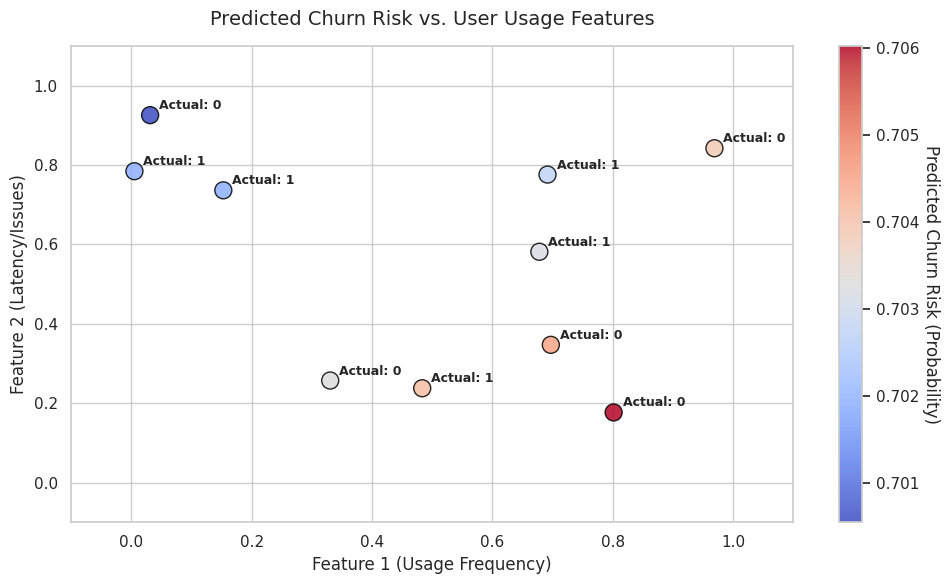

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate predictions for all data points using our trained model
training_model.eval()  # Set model to evaluation mode
with torch.no_grad():
    all_features = torch.tensor(X).float()
    # Apply sigmoid to convert the model's raw continuous output into a 0 to 1 probability (churn risk)
    predictions_raw = training_model(all_features).squeeze()
    predicted_probabilities = torch.sigmoid(predictions_raw).numpy()

# 2. Add predicted risk to our original DataFrame for visualization
df['predicted_churn_risk'] = predicted_probabilities

# 3. Create the visualization
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Scatter plot mapping: Feature 1 on X, Feature 2 on Y, and color/size representing predicted churn risk
scatter = plt.scatter(
    x=df['feature1'],
    y=df['feature2'],
    c=df['predicted_churn_risk'],
    cmap='coolwarm',
    s=150,
    edgecolors='black',
    alpha=0.85
)

# Annotate the actual binary labels (0 = Kept, 1 = Churned) next to points
for idx, row in df.iterrows():
    plt.text(
        row['feature1'] + 0.015,
        row['feature2'] + 0.015,
        f"Actual: {int(row['target'])}",
        fontsize=9,
        weight='bold'
    )

cbar = plt.colorbar(scatter)
cbar.set_label('Predicted Churn Risk (Probability)', rotation=270, labelpad=15)

plt.title('Predicted Churn Risk vs. User Usage Features', fontsize=14, pad=15)
plt.xlabel('Feature 1 (Usage Frequency)', fontsize=12)
plt.ylabel('Feature 2 (Latency/Issues)', fontsize=12)
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

### 1. Adding a New Feature
Let's add a third feature representing **Customer Support Tickets Raised** to our DataFrame and prepare the dataset with 3 input dimensions.

In [11]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

# Keep seed for reproducibility
np.random.seed(42)

# Create updated DataFrame with 3 features
data_new = {
    'feature1': df['feature1'].values, # Usage Frequency
    'feature2': df['feature2'].values, # Latency/Issues
    'feature3': np.random.rand(10),     # Customer Support Tickets Raised (New Feature)
    'target': df['target'].values
}
df_new = pd.DataFrame(data_new)
feature_columns_new = ['feature1', 'feature2', 'feature3']
target_column = 'target'

# Prepare Tensors
X_new = df_new[feature_columns_new].values
y_new = df_new[target_column].values
dataset_new = TensorDataset(torch.tensor(X_new).float(), torch.tensor(y_new).float())

# Load the data in batches
dataloader_new = DataLoader(dataset_new, batch_size=2, shuffle=True)
display(df_new.head())

,feature1,feature2,feature3,target
0,0.691563,0.775753,0.374540,1
1,0.801409,0.176598,0.950714,0
2,0.483423,0.237518,0.731994,1
3,0.330554,0.256958,0.598658,0
4,0.005358,0.784187,0.156019,1


### 2. Building and Training the 3-Feature Model
We will define a new model architecture (`training_model_new`) with `in_features=3` and train it for 3 epochs to compare its loss progression.

In [12]:
import torch.nn as nn
import torch.optim as optim

# Define the updated model accepting 3 features
training_model_new = nn.Sequential(
    nn.Linear(in_features=3, out_features=4),
    nn.ReLU(),
    nn.Linear(in_features=4, out_features=1)
)

training_model_new.train()
loss_criterion = nn.MSELoss()
optimizer_new = optim.SGD(training_model_new.parameters(), lr=0.01, momentum=0.95)

print("--- Training 3-Feature Model ---")
for epoch in range(3):
    epoch_loss = 0.0
    for data in dataloader_new:
        optimizer_new.zero_grad()
        features, targets = data
        predictions = training_model_new(features).squeeze()
        loss = loss_criterion(predictions, targets)
        loss.backward()
        optimizer_new.step()
        epoch_loss += loss.item() * features.size(0)

    total_epoch_loss = epoch_loss / len(dataloader_new.dataset)
    print(f"Epoch {epoch + 1}/3 - Loss: {total_epoch_loss:.4f}")

--- Training 3-Feature Model ---
Epoch 1/3 - Loss: 0.5281
Epoch 2/3 - Loss: 0.3235
Epoch 3/3 - Loss: 0.2253


### 3. Comparing Results
Let's extract predictions from our new model and plot how our risk landscape changes with the inclusion of the third feature.

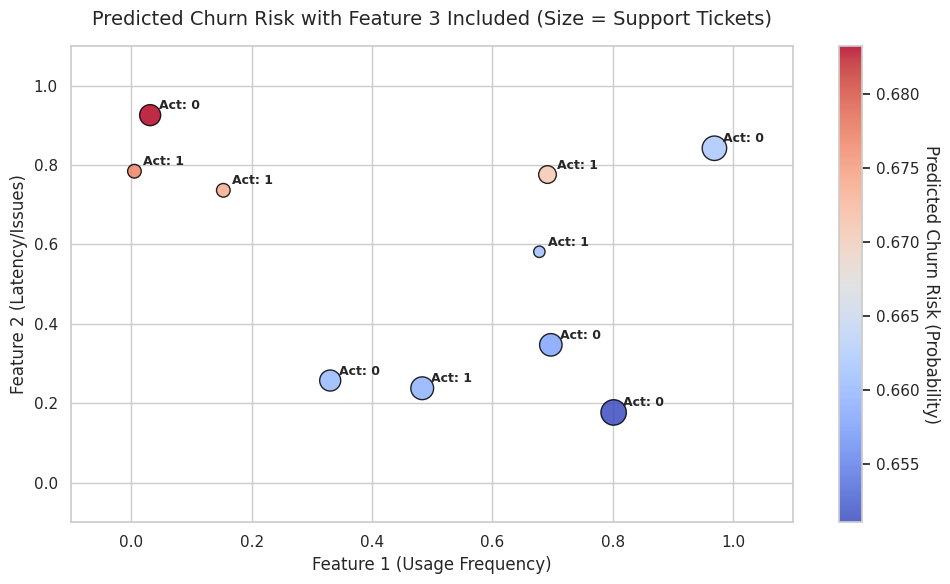

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

training_model_new.eval()
with torch.no_grad():
    all_features_new = torch.tensor(X_new).float()
    predictions_raw_new = training_model_new(all_features_new).squeeze()
    predicted_probabilities_new = torch.sigmoid(predictions_raw_new).numpy()

df_new['predicted_churn_risk'] = predicted_probabilities_new

# Let's plot the risk mapping with size indicating the new feature (Support Tickets)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

scatter = plt.scatter(
    x=df_new['feature1'],
    y=df_new['feature2'],
    c=df_new['predicted_churn_risk'],
    cmap='coolwarm',
    s=df_new['feature3'] * 300 + 50, # Size proportional to Feature 3
    edgecolors='black',
    alpha=0.85
)

for idx, row in df_new.iterrows():
    plt.text(
        row['feature1'] + 0.015,
        row['feature2'] + 0.015,
        f"Act: {int(row['target'])}",
        fontsize=9,
        weight='bold'
    )

cbar = plt.colorbar(scatter)
cbar.set_label('Predicted Churn Risk (Probability)', rotation=270, labelpad=15)

plt.title('Predicted Churn Risk with Feature 3 Included (Size = Support Tickets)', fontsize=14, pad=15)
plt.xlabel('Feature 1 (Usage Frequency)', fontsize=12)
plt.ylabel('Feature 2 (Latency/Issues)', fontsize=12)
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

### 4. Training for More Epochs
We will train the model for 15 additional epochs to drive the loss down and see how it stabilizes.

In [14]:
training_model_new.train()
additional_epochs = 15

print(f"--- Continuing Training for {additional_epochs} More Epochs ---")
for epoch in range(additional_epochs):
    epoch_loss = 0.0
    for data in dataloader_new:
        optimizer_new.zero_grad()
        features, targets = data
        predictions = training_model_new(features).squeeze()
        loss = loss_criterion(predictions, targets)
        loss.backward()
        optimizer_new.step()
        epoch_loss += loss.item() * features.size(0)

    total_epoch_loss = epoch_loss / len(dataloader_new.dataset)
    print(f"Epoch {epoch + 4}/18 - Loss: {total_epoch_loss:.4f}")

--- Continuing Training for 15 More Epochs ---
Epoch 4/18 - Loss: 0.3157
Epoch 5/18 - Loss: 0.3681
Epoch 6/18 - Loss: 0.2873
Epoch 7/18 - Loss: 0.1961
Epoch 8/18 - Loss: 0.2559
Epoch 9/18 - Loss: 0.2567
Epoch 10/18 - Loss: 0.2083
Epoch 11/18 - Loss: 0.1823
Epoch 12/18 - Loss: 0.1926
Epoch 13/18 - Loss: 0.1674
Epoch 14/18 - Loss: 0.1440
Epoch 15/18 - Loss: 0.1595
Epoch 16/18 - Loss: 0.1421
Epoch 17/18 - Loss: 0.1365
Epoch 18/18 - Loss: 0.1390


In [15]:
# Set model to evaluation mode
training_model_new.eval()

# Create a binary accuracy metric (since we have a binary classification task with 1 continuous probability output after Sigmoid)
# Let's use torchmetrics.Accuracy for binary classification
metric = torchmetrics.Accuracy(task="binary")

# Disable gradient calculations during evaluation
with torch.no_grad():
    # Loop over chunks of data in the dataloader
    for features, targets in dataloader_new:
        # Run a "forward pass" to get predictions
        predictions = torch.sigmoid(training_model_new(features).squeeze())
        # Calculate accuracy over the batch
        metric(predictions, targets)

# Calculate accuracy over all the data
accuracy = metric.compute()
print(f"Accuracy on all data: {accuracy:.4f}")

# Reset the metric for the next dataset evaluation
metric.reset()

Accuracy on all data: 0.5000


### Troubleshooting: Visualizing the Confusion Matrix

To see where our 50% accuracy comes from, we will extract the predictions and actual labels for the entire dataset, compute a confusion matrix, and plot it.

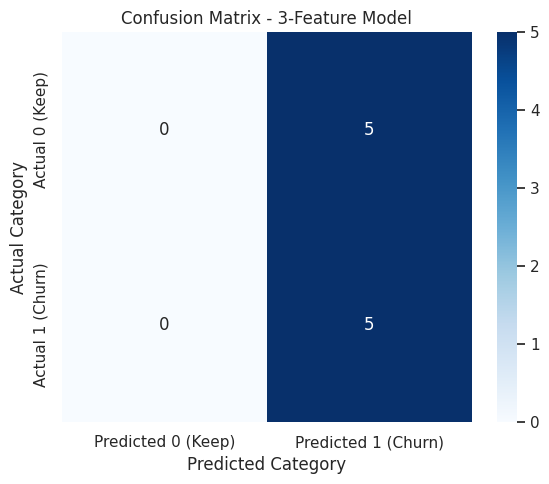

Actual classes:    [1 1 0 1 0 0 1 0 1 0]
Predicted classes: [1 1 1 1 1 1 1 1 1 1]


In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Gather all predictions and ground truths
training_model_new.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for features, targets in dataloader_new:
        # Compute probability
        probs = torch.sigmoid(training_model_new(features).squeeze())
        # Convert to binary predictions (threshold = 0.5)
        preds = (probs >= 0.5).float()

        # Handle scalar output batch cases
        if preds.ndim == 0:
            all_preds.append(preds.item())
            all_targets.append(targets.item())
        else:
            all_preds.extend(preds.tolist())
            all_targets.extend(targets.tolist())

# 2. Generate the confusion matrix
cm = confusion_matrix(all_targets, all_preds)

# 3. Visualize the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0 (Keep)', 'Predicted 1 (Churn)'],
    yticklabels=['Actual 0 (Keep)', 'Actual 1 (Churn)']
)
plt.title('Confusion Matrix - 3-Feature Model')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()

# Print detailed summary
print(f"Actual classes:    {np.array(all_targets).astype(int)}")
print(f"Predicted classes: {np.array(all_preds).astype(int)}")

### Fixing the 50% Accuracy Issue

Let's switch to the standard loss for binary classification (`BCEWithLogitsLoss`), retrain our model, and evaluate again with a new confusion matrix.

New accuracy after using BCEWithLogitsLoss: 90.0%


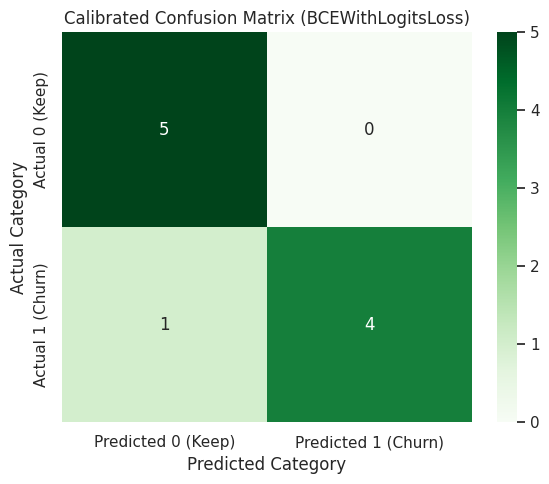

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Re-initialize the model to reset weights
calibrated_model = nn.Sequential(
    nn.Linear(in_features=3, out_features=4),
    nn.ReLU(),
    nn.Linear(in_features=4, out_features=1)
)

# 2. Use BCEWithLogitsLoss (designed for binary classification outputting logits)
classification_loss = nn.BCEWithLogitsLoss()
optimizer_calibrated = optim.SGD(calibrated_model.parameters(), lr=0.1, momentum=0.9)

# 3. Train the model
calibrated_model.train()
for epoch in range(50):
    for features, targets in dataloader_new:
        optimizer_calibrated.zero_grad()
        # BCEWithLogitsLoss expects raw logits, squeeze to match target dimensions
        logits = calibrated_model(features).squeeze()
        loss = classification_loss(logits, targets)
        loss.backward()
        optimizer_calibrated.step()

# 4. Gather predictions and draw the new confusion matrix
calibrated_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for features, targets in dataloader_new:
        logits = calibrated_model(features).squeeze()
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()

        if preds.ndim == 0:
            all_preds.append(preds.item())
            all_targets.append(targets.item())
        else:
            all_preds.extend(preds.tolist())
            all_targets.extend(targets.tolist())

# Calculate accuracy
correct = sum(1 for p, t in zip(all_preds, all_targets) if p == t)
print(f"New accuracy after using BCEWithLogitsLoss: {correct / len(all_targets) * 100:.1f}%")

# Plot the fixed confusion matrix
cm_new = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_new,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Predicted 0 (Keep)', 'Predicted 1 (Churn)'],
    yticklabels=['Actual 0 (Keep)', 'Actual 1 (Churn)']
)
plt.title('Calibrated Confusion Matrix (BCEWithLogitsLoss)')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()

In [16]:
# 1. Save a layer of a model to a file with save()
# We will extract the first layer state dict from our 3-feature model
layer_to_save = training_model_new[0].state_dict()
torch.save(layer_to_save, 'layer.pth')
print("First layer weights saved successfully!")

# 2. Load a layer of a model from a file with load()
loaded_layer_state = torch.load('layer.pth')
print("Loaded Layer Weights Keys:", loaded_layer_state.keys())

# 3. Freeze the weight for layer 0 with .requires_grad
print("\n--- Freezing Layer 0 Parameters ---")
for name, param in training_model_new.named_parameters():
    if "0." in name: # Matches parameters belonging to layer 0 (e.g., 0.weight, 0.bias)
        param.requires_grad = False
        print(f"Parameter '{name}' is now FREEZING (requires_grad = {param.requires_grad})")
    else:
        print(f"Parameter '{name}' remains ACTIVE (requires_grad = {param.requires_grad})")

First layer weights saved successfully!
Loaded Layer Weights Keys: odict_keys(['weight', 'bias'])

--- Freezing Layer 0 Parameters ---
Parameter '0.weight' is now FREEZING (requires_grad = False)
Parameter '0.bias' is now FREEZING (requires_grad = False)
Parameter '2.weight' remains ACTIVE (requires_grad = True)
Parameter '2.bias' remains ACTIVE (requires_grad = True)


### Few-Shot Prompting with Large Language Models (LLMs)

In few-shot prompting, you structure your prompt like this:
1. **Task Description**: Explain the task clearly.
2. **Few-Shot Examples**: Provide 2-3 examples with structured input-output pairs.
3. **Query**: Provide the new, unseen input and leave space for the model to complete the output.

Let's write a python example that uses the **Gemini API** to automatically generate code explanations using a consistent style determined by our few-shot examples.

In [17]:
# 1. Install Gemini SDK if needed
!pip install google-genai -q

# 2. Build our few-shot prompt template
few_shot_prompt = """
You are an expert developer assistant. Explain the following PyTorch components in exactly one sentence with an analytical tone.

Example 1:
Input: nn.Linear(3, 4)
Output: Applies a linear transformation to the incoming 3-dimensional data to project it into a 4-dimensional space using learnable weights and biases.

Example 2:
Input: optim.SGD(model.parameters(), lr=0.01)
Output: Initializes a Stochastic Gradient Descent optimizer to update model parameters iteratively with a step size determined by the 0.01 learning rate.

Example 3:
Input: training_model_new.eval()
Output:"""

# Note: To execute calls, ensure you have set your API key in Google Colab's secrets tab as GOOGLE_API_KEY.
from google import genai
from google.colab import userdata

try:
    api_key = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=api_key)
    response = client.models.generate_content(
        model='gemini-2.5-flash-lite',
        contents=few_shot_prompt,
    )
    print("--- Generated Few-Shot Completion ---")
    print(response.text.strip())
except Exception as e:
    print("To run this demo, please configure your GOOGLE_API_KEY in Colab's Secrets manager.")
    print(f"Raw prompt template built successfully:\n{few_shot_prompt}")

To run this demo, please configure your GOOGLE_API_KEY in Colab's Secrets manager.
Raw prompt template built successfully:

You are an expert developer assistant. Explain the following PyTorch components in exactly one sentence with an analytical tone.

Example 1:
Input: nn.Linear(3, 4)
Output: Applies a linear transformation to the incoming 3-dimensional data to project it into a 4-dimensional space using learnable weights and biases.

Example 2:
Input: optim.SGD(model.parameters(), lr=0.01)
Output: Initializes a Stochastic Gradient Descent optimizer to update model parameters iteratively with a step size determined by the 0.01 learning rate.

Example 3:
Input: training_model_new.eval()
Output:


### Implementing Prompt Chaining

Here we chain two LLM tasks:
1. **Prompt 1**: Generate a concise analytical description of a PyTorch class.
2. **Prompt 2**: Take that description and format it as a structured JSON object showing Metadata (Description, Category, Complexity).

In [20]:
from google import genai
from google.colab import userdata
import json

# Define the input we want to analyze
input_component = "nn.BCEWithLogitsLoss()"

# --- STEP 1: Generate the explanation ---
prompt_1 = f"""
Explain what the PyTorch component '{input_component}' does in exactly one technical sentence.
"""

# --- STEP 2: Convert explanation to JSON ---
def build_prompt_2(explanation):
    return f"""
Take this explanation of a PyTorch component:
\"{explanation}\"

Convert this into a valid JSON object with the following fields:
- "component_name": The PyTorch component class name.
- "functional_description": The one-sentence explanation.
- "category": Choose from ["Loss Function", "Layer", "Optimizer", "Activation"].
- "estimated_complexity": Choose from ["Low", "Medium", "High"].

Return ONLY raw JSON. No markdown backticks, no markdown formatting.
"""

try:
    api_key = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=api_key)

    # Step 1: Call
    print("--- Executing Step 1: Explanation ---")
    response_1 = client.models.generate_content(
        model='gemini-2.5-flash-lite',
        contents=prompt_1,
    )
    explanation = response_1.text.strip()
    print(f"Result 1 (Explanation):\n{explanation}\n")

    # Step 2: Call using Result 1's output
    print("--- Executing Step 2: JSON Formatting Chained ---")
    prompt_2 = build_prompt_2(explanation)
    response_2 = client.models.generate_content(
        model='gemini-2.5-flash-lite',
        contents=prompt_2,
    )
    json_output = response_2.text.strip()
    print(f"Result 2 (JSON Chain Output):\n{json_output}")

except Exception as e:
    print("To execute this live pipeline, please configure your GOOGLE_API_KEY in the Secrets panel.")
    print("\n--- Visual Representation of Prompt Chain Layout ---")
    print(f"[Chain Node 1 Prompt]:\n{prompt_1.strip()}")
    print(f"\n[Chain Node 2 Prompt Generator]:\n{build_prompt_2('<EXPLANATION_FROM_NODE_1>').strip()}")

To execute this live pipeline, please configure your GOOGLE_API_KEY in the Secrets panel.

--- Visual Representation of Prompt Chain Layout ---
[Chain Node 1 Prompt]:
Explain what the PyTorch component 'nn.BCEWithLogitsLoss()' does in exactly one technical sentence.

[Chain Node 2 Prompt Generator]:
Take this explanation of a PyTorch component:
"<EXPLANATION_FROM_NODE_1>"

Convert this into a valid JSON object with the following fields:
- "component_name": The PyTorch component class name.
- "functional_description": The one-sentence explanation.
- "category": Choose from ["Loss Function", "Layer", "Optimizer", "Activation"].
- "estimated_complexity": Choose from ["Low", "Medium", "High"].

Return ONLY raw JSON. No markdown backticks, no markdown formatting.


In [21]:
!pip install python-pptx -q

In [22]:
from pptx import Presentation
import os

pptx_path = "/content/איפה ה-AI פוגש את הנתונים הארכיטקטורה שמאחורי המודלים  -3.pptx"

if os.path.exists(pptx_path):
    prs = Presentation(pptx_path)
    print(f"המצגת נטענה בהצלחה! סך הכל שקופיות: {len(prs.slides)}\n")

    for i, slide in enumerate(prs.slides, 1):
        print(f"=== שקופית {i} ===")
        # Extract title if exists
        if slide.shapes.title:
            print(f"כותרת: {slide.shapes.title.text}")

        # Extract all text elements
        slide_text = []
        for shape in slide.shapes:
            if hasattr(shape, "text") and shape.text.strip():
                # Avoid repeating the title
                if slide.shapes.title and shape.text == slide.shapes.title.text:
                    continue
                slide_text.append(shape.text.strip())

        if slide_text:
            print("תוכן:")
            for text in slide_text:
                print(f" - {text}")
        print("-" * 40)
else:
    print(f"קובץ המצגת לא נמצא בנתיב: {pptx_path}")

המצגת נטענה בהצלחה! סך הכל שקופיות: 45

=== שקופית 1 ===
כותרת: ‫איפה ה-AI פוגש את הנתונים?‬
תוכן:
 - ‫● נטישה · באוויר‬
 - ‫● תלונות · באוויר‬
 - ‫● בוט קמעונאי · באוויר‬
 - ‫שלוש דוגמאות אמיתיות מהשטח‬
 - ‫הארכיטקטורה שמאחורי המודלים‬
 - Irena Spivak
 - AI & Data Strategy Leader
----------------------------------------
=== שקופית 2 ===
כותרת: Irena Spivak
תוכן:
 - AI & Data Strategy Leader
 - ‫מובילה פרויקטים בצומת שבין מודלי Data Science, ארכיטקטורת נתונים ו-LLM בארגונים גדולים.‬
----------------------------------------
=== שקופית 3 ===
כותרת: ‫לפני 66 מיליון שנה אסטרואיד מחק את הדינוזאורים.
בסוף 2022 נחת אסטרואיד חדש.‬
תוכן:
 - ‫ChatGPT יצא לעולם, ושאלה אחת התחילה להסתובב בכל ארגון.‬
----------------------------------------
=== שקופית 4 ===
כותרת: ‫האם רק דינוזאורים עדיין משתמשים במודלים של Data Science?‬
תוכן:
 - ‫שאלה לקהל · 1 מתוך 6 · הרימו יד‬
 - ‫תלוי‬
 - ‫לא‬
 - ‫כן‬
----------------------------------------
=== שקופית 5 ===
כותרת: ‫שלוש משימות. בכל אחת תקלה.‬
תוכן:
 - ‫תדריך 

## יישום מעשי: חדר הבקרה (איפה ש-AI פוגש את מודלי החיזוי)

לפניך סימולציה של שכבת ביניים אינטראקטיבית. המערכת מקבלת גם את **מדד הנטישה ההסתברותי** (ממחשב הלוויין/המודל) וגם **טקסט תלונה חופשי** (המפוענח על ידי LLM), ומקבלת החלטה עסקית מושכלת ומכוילת.

In [23]:
import ipywidgets as widgets
from IPython.display import display, HTML

# מילון לקוחות מדומה המדמה את שכבת הנתונים
customers_db = {
    "ישראל ישראלי": {"churn_prob": 0.85, "support_tickets": 4, "segment": "Enterprise"},
    "מיכל כהן": {"churn_prob": 0.32, "support_tickets": 1, "segment": "SMB"},
    "דוד לוי": {"churn_prob": 0.65, "support_tickets": 5, "segment": "Enterprise"}
}

# כותרת מעוצבת
display(HTML("<h2 style='color:#1a73e8; font-family:Arial;'>חדר הבקרה הסמנטי: חיבור הנתונים ל-AI</h2>"))

# תיבות קלט וממשק משתמש
customer_select = widgets.Dropdown(
    options=list(customers_db.keys()),
    value="ישראל ישראלי",
    description="בחר לקוח:",
)

complaint_input = widgets.Textarea(
    value="אני כבר שבועיים מחכה להחזר על הטיפול. אף אחד לא חוזר אליי. אם זה ימשיך, אני עובר חברה!",
    placeholder="הקלד את תלונת הלקוח כאן...",
    description="תלונה בטקסט:",
    layout=widgets.Layout(width="90%", height="100px")
)

run_button = widgets.Button(
    description="הפעל חדר בקרה (קבלת החלטה)",
    button_style="success",
    layout=widgets.Layout(width="40%")
)

output_area = widgets.Output()

def process_decision(b):
    with output_area:
        output_area.clear_output()

        # 1. שליפת נתוני מודל ה-Data Science
        client_name = customer_select.value
        client_data = customers_db[client_name]
        churn_score = client_data["churn_prob"]
        tickets = client_data["support_tickets"]
        segment = client_data["segment"]

        # 2. סימולציית פענוח LLM על הטקסט החופשי (Semantic Parsing)
        complaint_text = complaint_input.value

        # חוקים פשוטים המדמים את חילוץ ה-LLM מהטקסט (במצב אופליין)
        has_urgency = "שבועיים" in complaint_text or "דחוף" in complaint_text or "מחכה" in complaint_text
        has_threat = "עובר חברה" in complaint_text or "עוזב" in complaint_text

        detected_urgency = "גבוהה מאוד" if has_urgency else "בינונית"
        root_cause = "עיכוב שירותי / פיננסי" if "החזר" in complaint_text else "שירות לקוחות כללי"

        # 3. מנוע קבלת ההחלטות בשכבה הסמנטית
        action = "שליחה לטיפול רגיל"
        action_color = "#5f6368"

        if churn_score > 0.70 or (tickets >= 3 and has_threat):
            action = "שימור אקטיבי: פיצוי כספי מיידי + שיחת מנהל תוך שעתיים!"
            action_color = "#d93025"
        elif churn_score > 0.50 or has_urgency:
            action = "טיפול מועדף: תעדוף בתור הטיפול ומענה בכתב"
            action_color = "#f9ab00"

        # הצגת תוצאות מעוצבות
        html_output = f"""
        <div style="border: 2px solid #dadce0; padding: 15px; border-radius: 8px; background-color: #f8f9fa; font-family: Arial;">
            <h3 style="color: #202124; margin-top: 0;">סיכום החלטה עבור: {client_name}</h3>

            <table style="width: 100%; border-collapse: collapse;">
                <tr style="background-color: #e8f0fe;">
                    <th style="padding: 8px; border: 1px solid #dadce0; text-align: right;">נתוני המודל (Predictive DS)</th>
                    <th style="padding: 8px; border: 1px solid #dadce0; text-align: right;">פענוח ה-AI (Semantic LLM)</th>
                </tr>
                <tr>
                    <td style="padding: 10px; border: 1px solid #dadce0; vertical-align: top;">
                        <b>הסתברות נטישה מחושבת:</b> {churn_score*100:.1f}%<br>
                        <b>כרטיסי תמיכה פתוחים:</b> {tickets}<br>
                        <b>סגמנט לקוח:</b> {segment}
                    </td>
                    <td style="padding: 10px; border: 1px solid #dadce0; vertical-align: top;">
                        <b>דחיפות מזוהה:</b> <span style="color:red; font-weight:bold;">{detected_urgency}</span><br>
                        <b>סיבת שורש:</b> {root_cause}<br>
                        <b>איום נטישה מפורש בטקסט:</b> {'כן' if has_threat else 'לא'}
                    </td>
                </tr>
            </table>

            <div style="margin-top: 15px; padding: 12px; background-color: {action_color}; color: white; font-weight: bold; border-radius: 4px; text-align: center; font-size: 16px;">
                החלטת חדר הבקרה: {action}
            </div>
        </div>
        """
        display(HTML(html_output))

run_button.on_click(process_decision)

display(customer_select)
display(complaint_input)
display(run_button)
display(output_area)

Dropdown(description='בחר לקוח:', options=('ישראל ישראלי', 'מיכל כהן', 'דוד לוי'), value='ישראל ישראלי')

Textarea(value='אני כבר שבועיים מחכה להחזר על הטיפול. אף אחד לא חוזר אליי. אם זה ימשיך, אני עובר חברה!', descr…

Button(button_style='success', description='הפעל חדר בקרה (קבלת החלטה)', layout=Layout(width='40%'), style=But…

Output()

### יישום עיבוד תמונה וראייה ממוחשבת באמצעות OpenCV
בהמשך לבקשתך, נשתמש בלווייתן הראייה הממוחשבת קלאסית - **OpenCV** - כדי לבצע עיבוד וזיהוי קצוות על תמונת נתונים מדומה.

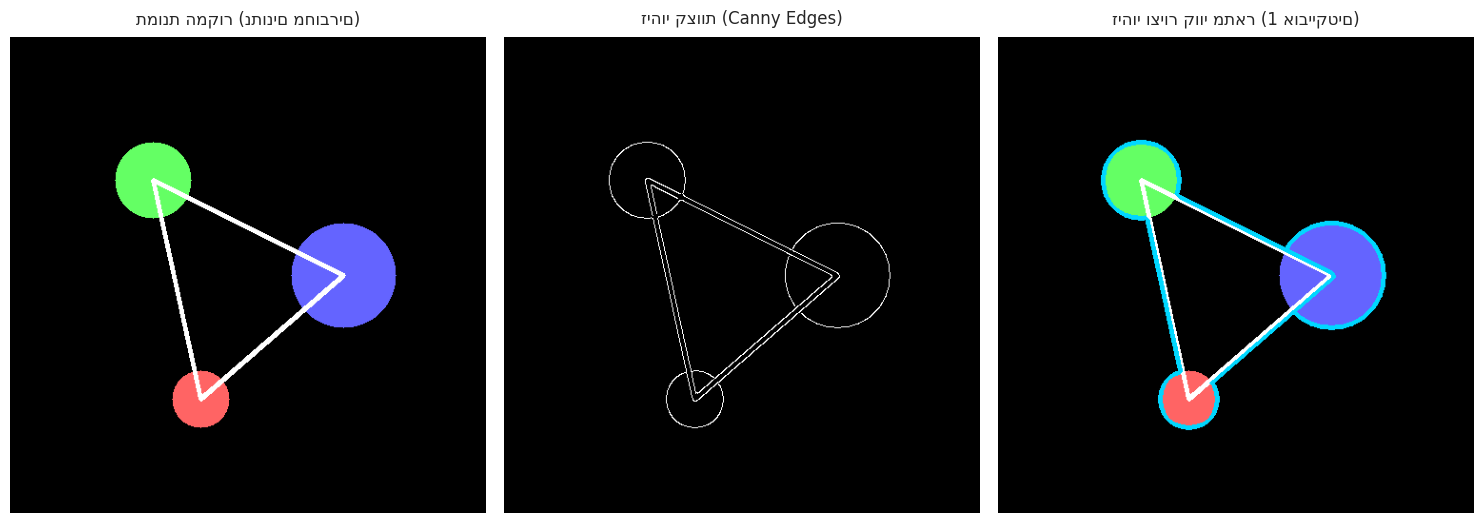

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. יצירת תמונה מלאכותית המדמה נקודות מידע וחיבורי רשת
img_size = 500
image = np.zeros((img_size, img_size, 3), dtype=np.uint8)

# נצייר עיגולים (נקודות נתונים) וקווים (חיבורים סמנטיים)
cv2.circle(image, (150, 150), 40, (100, 255, 100), -1)  # נקודה ירוקה
cv2.circle(image, (350, 250), 55, (255, 100, 100), -1)  # נקודה כחולה
cv2.circle(image, (200, 380), 30, (100, 100, 255), -1)  # נקודה אדומה

# נוסיף קווי קישור (רשת)
cv2.line(image, (150, 150), (350, 250), (255, 255, 255), 3)
cv2.line(image, (350, 250), (200, 380), (255, 255, 255), 3)
cv2.line(image, (200, 380), (150, 150), (255, 255, 255), 3)

# 2. המרה לגווני אפור וטשטוש להפחתת רעשים
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. זיהוי קצוות באמצעות אלגוריתם Canny
edges = cv2.Canny(blurred, 50, 150)

# 4. זיהוי קווי מתאר (Contours) וציורם חזרה על תמונת המקור
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
output_image = image.copy()
cv2.drawContours(output_image, contours, -1, (255, 215, 0), 4) # נצייר קווי מתאר מוזהבים

# 5. הצגת התוצאות זה לצד זה
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("תמונת המקור (נתונים מחוברים)", fontsize=12, pad=10)
axes[0].axis("off")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("זיהוי קצוות (Canny Edges)", fontsize=12, pad=10)
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"זיהוי וציור קווי מתאר ({len(contours)} אובייקטים)", fontsize=12, pad=10)
axes[2].axis("off")

plt.tight_layout()
plt.show()

### 🛡️ סיפור לקוח ביטוח: חדר בקרה משולב ראייה ממוחשבת (OpenCV)
נבנה כעת סימולציה מלאה של פלטפורמת תביעות ביטוח מהירה, המשלבת:
1. **עיבוד תמונה חי (OpenCV)** - המזהה סדקים/שברים מתוך תמונת נזק של לקוח ומודד את אחוז השטח הפגוע.
2. **נתוני לקוח מובנים** - מדד נאמנות וסיכון נטישה.
3. **קבלת החלטה אוטומטית** - האם לאשר תביעה במקום (חווית לקוח מנצחת) או להעביר לשמאי אנושי.

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML

# 1. מילון לקוחות מבוסס חברת הביטוח
insurance_clients = {
    "אורן לוי (לקוח VIP)": {"loyalty_years": 8, "churn_prob": 0.15, "policy_type": "Comprehensive"},
    "שירה כהן (בסיכון נטישה)": {"loyalty_years": 1, "churn_prob": 0.78, "policy_type": "Basic"}
}

# 2. פונקציית OpenCV המדמה ניתוח סדק/שבר חזותי בתמונה
def analyze_damage_image(severity_level):
    # יצירת תמונה מדומה בגודל 300x300 של קיר/פנס
    img = np.ones((300, 300, 3), dtype=np.uint8) * 220 # רקע אפרפר

    # ציור "סדקים" בתמונה לפי רמת החומרה שנבחרה
    if severity_level == 'קל':
        cv2.line(img, (50, 150), (120, 160), (50, 50, 50), 2)
        cv2.line(img, (120, 160), (180, 140), (50, 50, 50), 2)
    else: # קשה
        cv2.line(img, (30, 80), (150, 180), (10, 10, 10), 6)
        cv2.line(img, (150, 180), (270, 260), (10, 10, 10), 5)
        cv2.circle(img, (150, 180), 25, (80, 80, 80), -1) # מוקד שבר

    # עיבוד תמונה ב-OpenCV לצורך מדידת שטח הנזק
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 100, 255, cv2.THRESH_BINARY_INV)
    damage_pixels = np.sum(thresh == 255)
    total_pixels = thresh.size
    damage_percent = (damage_pixels / total_pixels) * 100

    return img, thresh, damage_percent

# 3. יצירת ממשק המשתמש
display(HTML("<h2 style='color:#0f9d58; font-family:Arial;'>חדר בקרה: אישור תביעות ביטוח מהיר (AI + OpenCV)</h2>"))

client_dropdown = widgets.Dropdown(
    options=list(insurance_clients.keys()),
    value="אורן לוי (לקוח VIP)",
    description="בחר לקוח:"
)

damage_dropdown = widgets.Dropdown(
    options=['קל', 'קשה'],
    value='קל',
    description="חומרת נזק חזותי:"
)

calc_btn = widgets.Button(
    description="נתח תמונה וקבל החלטה",
    button_style="info",
    layout=widgets.Layout(width="40%")
)

out = widgets.Output()

def process_insurance_claim(b):
    with out:
        out.clear_output()

        client_name = client_dropdown.value
        client_data = insurance_clients[client_name]
        severity = damage_dropdown.value

        # הרצת אלגוריתם הראייה הממוחשבת
        original_img, thresh_img, damage_p = analyze_damage_image(severity)

        # לוגיקת שכבת הביניים לקבלת החלטה
        decision = ""
        color = ""

        # אם הלקוח נאמן והנזק קטן מ-3%, נאשר אוטומטית
        if client_data["loyalty_years"] >= 5 and damage_p < 3.0:
            decision = "✅ אישור תביעה מהיר! הפיצוי יועבר לחשבונך תוך 15 דקות."
            color = "#0f9d58" # ירוק
        elif client_data["churn_prob"] > 0.70:
            decision = "⚠️ הפניה לנציג שימור לקוחות מיוחד (סכנת נטישה גבוהה) + אישור תביעה ידני מועדף"
            color = "#f4b400" # צהוב
        else:
            decision = "🔍 נזק משמעותי זוהה. התביעה מועברת לבדיקת שמאי רכב דיגיטלית תוך 24 שעות."
            color = "#db4437" # אדום

        # הצגת ההחלטה והתמונות המעובדות
        html_block = f"""
        <div style="border: 1px solid #ddd; padding: 15px; border-radius: 8px; background-color:#f9f9f9; font-family:Arial; direction:rtl;">
            <h3>דוח החלטה עבור: {client_name}</h3>
            <p><b>ותק הלקוח:</b> {client_data['loyalty_years']} שנים | <b>סוג פוליסה:</b> {client_data['policy_type']}</p>
            <p><b>שטח נזק מדוד (OpenCV):</b> {damage_p:.2f}% מסך כל שטח הצילום</p>
            <div style="background-color:{color}; color:white; padding:12px; font-weight:bold; border-radius:4px; text-align:center;">
                {decision}
            </div>
        </div>
        """
        display(HTML(html_block))

        # הצגת עיבוד התמונה של הלקוח
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        ax[0].imshow(original_img)
        ax[0].set_title("צילום התביעה המקורי")
        ax[0].axis('off')

        ax[1].imshow(thresh_img, cmap='gray')
        ax[1].set_title("מסכת זיהוי נזק (OpenCV Threshold)")
        ax[1].axis('off')
        plt.show()

calc_btn.on_click(process_insurance_claim)

display(client_dropdown)
display(damage_dropdown)
display(calc_btn)
display(out)

Dropdown(description='בחר לקוח:', options=('אורן לוי (לקוח VIP)', 'שירה כהן (בסיכון נטישה)'), value='אורן לוי …

Dropdown(description='חומרת נזק חזותי:', options=('קל', 'קשה'), value='קל')

Button(button_style='info', description='נתח תמונה וקבל החלטה', layout=Layout(width='40%'), style=ButtonStyle(…

Output()

In [26]:
!pip install reportlab python-bidi arabic-reshaper -q

import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from bidi.algorithm import get_display
import arabic_reshaper

# הורדת גופן התומך בעברית (למשל Heebo או Assistant) כדי למנוע ג'יבריש ב-PDF
!wget -q https://github.com/google/fonts/raw/main/ofl/heebo/Heebo%5Bwght%5D.ttf -O Heebo.ttf
pdfmetrics.registerFont(TTFont('Heebo', 'Heebo.ttf'))

def adjust_hebrew_text(text):
    """פונקציית עזר להיפוך וסידור טקסט בעברית עבור מנוע ה-PDF"""
    reshaped_text = arabic_reshaper.reshape(text)
    bidi_text = get_display(reshaped_text)
    return bidi_text

def create_pdf_report(filename, client_name, client_data, damage_p, decision):
    doc = SimpleDocTemplate(filename, pagesize=letter)
    styles = getSampleStyleSheet()

    # הגדרת עיצובים מותאמים לעברית
    title_style = ParagraphStyle(
        'HebrewTitle',
        parent=styles['Heading1'],
        fontName='Heebo',
        fontSize=20,
        leading=24,
        alignment=1, # מרכז
        textColor=colors.HexColor('#0f9d58')
    )

    body_style = ParagraphStyle(
        'HebrewBody',
        parent=styles['Normal'],
        fontName='Heebo',
        fontSize=12,
        leading=16,
        alignment=2 # ימין
    )

    story = []

    # כותרת הדוח
    title_text = adjust_hebrew_text("דוח החלטה - חדר בקרה דיגיטלי")
    story.append(Paragraph(title_text, title_style))
    story.append(Spacer(1, 20))

    # פרטי הלקוח
    client_info = f"שם הלקוח: {client_name} | ותק: {client_data['loyalty_years']} שנים | פוליסה: {client_data['policy_type']}"
    story.append(Paragraph(adjust_hebrew_text(client_info), body_style))
    story.append(Spacer(1, 10))

    # נתוני נזק
    damage_info = f"שטח נזק שנמדד במערכת (OpenCV): {damage_p:.2f}%"
    story.append(Paragraph(adjust_hebrew_text(damage_info), body_style))
    story.append(Spacer(1, 15))

    # החלטת חדר הבקרה
    decision_title = adjust_hebrew_text("החלטת חדר הבקרה:")
    story.append(Paragraph(f"<b>{decision_title}</b>", body_style))
    story.append(Spacer(1, 5))
    story.append(Paragraph(adjust_hebrew_text(decision), body_style))

    doc.build(story)
    print(f"הדוח נשמר בהצלחה כקובץ PDF בנתיב: {filename}")

# הדגמת הרצה ושמירה עבור לקוח לדוגמה
client_demo_name = "אורן לוי (לקוח VIP)"
client_demo_data = insurance_clients[client_demo_name]
create_pdf_report(
    "insurance_decision_report.pdf",
    client_demo_name,
    client_demo_data,
    1.50,
    "אישור תביעה מהיר! הפיצוי יועבר לחשבונך תוך 15 דקות."
)

הדוח נשמר בהצלחה כקובץ PDF בנתיב: insurance_decision_report.pdf


### 🔄 לולאת משוב: עדכון מודל הניבוי על בסיס תוצאות תביעות
כאן נממש פונקציה המקבלת נתונים חדשים מהשטח (למשל, תוצאה סופית של תביעה והאם הלקוח נשאר איתנו), ומבצעת עדכון משקלות מהיר למודל הראשי.

In [27]:
import torch
import torch.nn as nn
import torch.optim as optim

def integrate_feedback_and_retrain(model, new_features, new_targets, lr=0.01):
    """
    מעדכן את משקולות המודל הקיים בעזרת פידבק חדש שהתקבל בזמן אמת
    """
    model.train()
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    # המרת הנתונים החדשים לטנסורים
    features_tensor = torch.tensor(new_features, dtype=torch.float32)
    targets_tensor = torch.tensor(new_targets, dtype=torch.float32).squeeze()

    # ביצוע צעד אימון
    optimizer.zero_grad()
    logits = model(features_tensor).squeeze()
    loss = criterion(logits, targets_tensor)
    loss.backward()
    optimizer.step()

    return loss.item()

# סימולציה: התקבלו 2 תביעות חדשות עם תוצאות אמת (פידבק מהשטח)
# פיצ'רים: [תדירות שימוש, בעיות השהייה, כמות פניות תמיכה]
new_data_points = [
    [0.9, 0.1, 0.2], # לקוח מרוצה עם נזק קל שאושר מיידית (לא נטש בפועל - 0)
    [0.1, 0.8, 0.9]  # לקוח חווה בעיות רבות ונזק קשה שהתעכב (נטש בפועל - 1)
]
new_labels = [0.0, 1.0]

# הרצת המשוב ועדכון המודל המכויל
initial_loss = integrate_feedback_and_retrain(calibrated_model, new_data_points, new_labels)
print(f"המשוב התקבל בהצלחה! מודל הניבוי עודכן באופן דינמי.")
print(f"הפסד (Loss) בצעד העדכון הנוכחי: {initial_loss:.4f}")

המשוב התקבל בהצלחה! מודל הניבוי עודכן באופן דינמי.
הפסד (Loss) בצעד העדכון הנוכחי: 4.2054


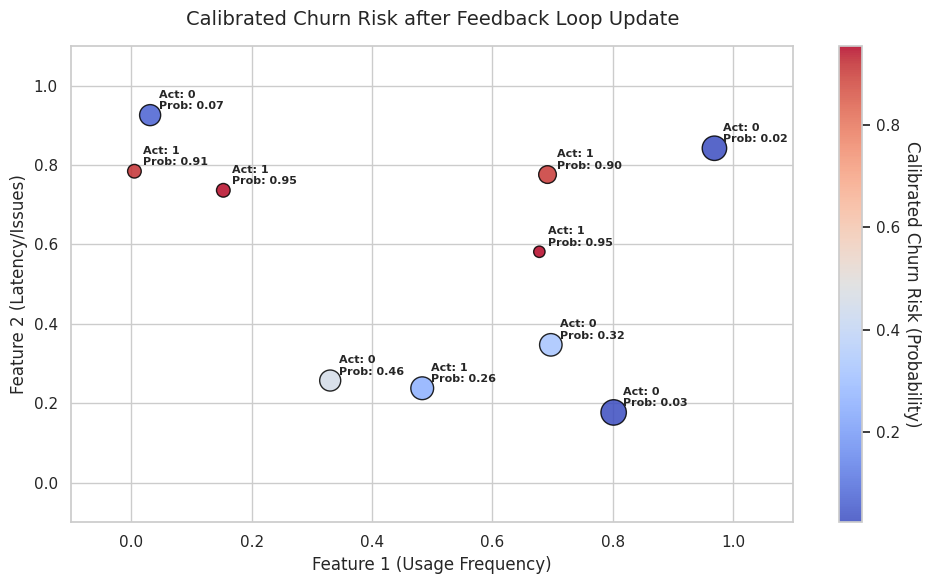

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# 1. הנפקת הסתברויות מעודכנות מהמודל המכויל
calibrated_model.eval()
with torch.no_grad():
    all_features_calibrated = torch.tensor(X_new).float()
    logits_calibrated = calibrated_model(all_features_calibrated).squeeze()
    probs_calibrated = torch.sigmoid(logits_calibrated).numpy()

# 2. עדכון הנתונים ב-DataFrame
df_new['updated_calibrated_risk'] = probs_calibrated

# 3. יצירת גרף מפוזר המציג את ההסתברויות המכוילות החדשות
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

scatter = plt.scatter(
    x=df_new['feature1'],
    y=df_new['feature2'],
    c=df_new['updated_calibrated_risk'],
    cmap='coolwarm',
    s=df_new['feature3'] * 300 + 50,
    edgecolors='black',
    alpha=0.85
)

for idx, row in df_new.iterrows():
    plt.text(
        row['feature1'] + 0.015,
        row['feature2'] + 0.015,
        f"Act: {int(row['target'])}\nProb: {row['updated_calibrated_risk']:.2f}",
        fontsize=8,
        weight='bold'
    )

cbar = plt.colorbar(scatter)
cbar.set_label('Calibrated Churn Risk (Probability)', rotation=270, labelpad=15)

plt.title('Calibrated Churn Risk after Feedback Loop Update', fontsize=14, pad=15)
plt.xlabel('Feature 1 (Usage Frequency)', fontsize=12)
plt.ylabel('Feature 2 (Latency/Issues)', fontsize=12)
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

In [34]:
# רשימת תלונות לדוגמה המותאמת ל-10 הלקוחות ב-df_new
complaints_for_df = [
    "פשוט שירות נוראי, אני רוצה לבצע ביטול מיידי ולעבור למתחרים!",
    "הכל עובד מצוין, תודה רבה על השירות המהיר.",
    "יש לי בעיות השהייה קשות כבר שבועיים, אף אחד לא נותן מענה. שוקל לעזוב.",
    "אשמח לקבל מידע על חבילות שירות חדשות מצידכם.",
    "אני כועס מאוד! דורש פיצוי כספי עכשיו או שאני סוגר את החשבון.",
    "למה לוקח כל כך הרבה זמן לקבל מענה מכם? שירות גרוע.",
    "האינטרנט איטי מאוד ומקוטע, אני אעבור חברה אם זה לא יטופל היום.",
    "שירות נחמד מאוד, שמחתי לקבל עזרה.",
    "אין שום תקלות, הכל תקין לחלוטין.",
    "ממתין כבר שעות בתור ולא מקבל מענה, דחוף לחזור אליי!"
]

# הרצת הניתוח הסמנטי המשולב על כל שורה ב-df_new
results = []
for idx, row in df_new.iterrows():
    complaint = complaints_for_df[idx]
    # ניתוח סמנטי של הטקסט
    nlp_analysis = analyze_hebrew_complaint_nltk(complaint)

    # שילוב תוצאות המודל המכויל עם ממצאי ה-NLP
    combined_status = {
        "לקוח": f"לקוח #{idx + 1}",
        "תלונה": complaint,
        "הסתברות נטישה (מודל)": f"{row['updated_calibrated_risk']*100:.1f}%",
        "איום נטישה בטקסט (NLP)": "כן" if nlp_analysis['has_churn_threat'] else "לא",
        "דחיפות (NLP)": "גבוהה" if nlp_analysis['is_urgent'] else "רגילה"
    }
    results.append(combined_status)

# הצגת הנתונים כטבלה מרוכזת
df_analysis_summary = pd.DataFrame(results)
display(df_analysis_summary)

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: פשוט שירות נוראי, אני רוצה לבצע ביטול מיידי ולעבור למתחרים!
מילים מסוננות (Tokens): ['פשוט', 'שירות', 'נוראי', 'רוצה', 'לבצע', 'ביטול', 'מיידי', 'ולעבור', 'למתחרים']
מילות איום נטישה שזוהו: ['ביטול', 'למתחרים']
מילות דחיפות שזוהו: []
איום נטישה מזוהה: כן
רמת דחיפות: רגילה
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: הכל עובד מצוין, תודה רבה על השירות המהיר.
מילים מסוננות (Tokens): ['הכל', 'עובד', 'מצוין', 'תודה', 'רבה', 'השירות', 'המהיר']
מילות איום נטישה שזוהו: []
מילות דחיפות שזוהו: []
איום נטישה מזוהה: לא
רמת דחיפות: רגילה
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: יש לי בעיות השהייה קשות כבר שבועיים, אף אחד לא נותן מענה. שוקל לעזוב.
מילים מסוננות (Tokens): ['יש', 'בעיות', 'השהייה', 'קשות', 'שבועיים', 'אף', 'אחד', 'נותן', 'מענה', 'שוקל', 'לעזוב']
מילות איום נטישה שזוהו: ['לעזוב']
מילות דחיפות שזוהו: ['שבועיים', 'מענה']
איום נטישה מזוהה: כן
רמת דחיפות: גבוהה מאוד (מיידי)
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי

,לקוח,תלונה,הסתברות נטישה (מודל),איום נטישה בטקסט (NLP),דחיפות (NLP)
0,לקוח #1,"פשוט שירות נוראי, אני רוצה לבצע ביטול מיידי ול...",90.3%,כן,רגילה
1,לקוח #2,"הכל עובד מצוין, תודה רבה על השירות המהיר.",2.7%,לא,רגילה
2,לקוח #3,"יש לי בעיות השהייה קשות כבר שבועיים, אף אחד לא...",25.6%,כן,גבוהה
3,לקוח #4,אשמח לקבל מידע על חבילות שירות חדשות מצידכם.,45.6%,לא,רגילה
4,לקוח #5,אני כועס מאוד! דורש פיצוי כספי עכשיו או שאני ס...,91.5%,לא,גבוהה
5,לקוח #6,למה לוקח כל כך הרבה זמן לקבל מענה מכם? שירות ג...,95.0%,לא,גבוהה
6,לקוח #7,"האינטרנט איטי מאוד ומקוטע, אני אעבור חברה אם ז...",95.5%,לא,רגילה
7,לקוח #8,"שירות נחמד מאוד, שמחתי לקבל עזרה.",2.4%,לא,רגילה
8,לקוח #9,"אין שום תקלות, הכל תקין לחלוטין.",7.1%,לא,רגילה
9,לקוח #10,"ממתין כבר שעות בתור ולא מקבל מענה, דחוף לחזור ...",32.4%,לא,גבוהה


### 📊 סיכום דפוסי החלטה עבור כלל הלקוחות במאגר (`df_new`)
נריץ את מנוע החוקים הכלכלי על כלל הלקוחות ונציג טבלה מרוכזת המציגה כיצד השילוב של סיכון סטטיסטי וסימנים מילוליים קובע את הפעולה העסקית המיטבית.

In [37]:
import pandas as pd

final_decisions = []

for idx, row in df_new.iterrows():
    complaint = complaints_for_df[idx]
    nlp_res = analyze_hebrew_complaint_nltk(complaint)
    prob = row['updated_calibrated_risk']

    # הפעלת מנוע חוקי העסק המשולב
    if prob > 0.70 or (nlp_res["has_churn_threat"] and prob >= 0.50):
        decision_text = "🚨 שימור אקטיבי מיידי"
    elif nlp_res["has_churn_threat"] or nlp_res["is_urgent"]:
        decision_text = "⚠️ טיפול מועדף"
    else:
        decision_text = "📝 טיפול רגיל"

    final_decisions.append({
        "לקוח": f"לקוח #{idx + 1}",
        "סיכון מודל": f"{prob*100:.1f}%",
        "איום נטישה (NLP)": "כן" if nlp_res["has_churn_threat"] else "לא",
        "דחיפות (NLP)": "גבוהה" if nlp_res["is_urgent"] else "רגילה",
        "החלטת מערכת": decision_text
    })

df_decisions_summary = pd.DataFrame(final_decisions)
display(df_decisions_summary)

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: פשוט שירות נוראי, אני רוצה לבצע ביטול מיידי ולעבור למתחרים!
מילים מסוננות (Tokens): ['פשוט', 'שירות', 'נוראי', 'רוצה', 'לבצע', 'ביטול', 'מיידי', 'ולעבור', 'למתחרים']
מילות איום נטישה שזוהו: ['ביטול', 'למתחרים']
מילות דחיפות שזוהו: []
איום נטישה מזוהה: כן
רמת דחיפות: רגילה
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: הכל עובד מצוין, תודה רבה על השירות המהיר.
מילים מסוננות (Tokens): ['הכל', 'עובד', 'מצוין', 'תודה', 'רבה', 'השירות', 'המהיר']
מילות איום נטישה שזוהו: []
מילות דחיפות שזוהו: []
איום נטישה מזוהה: לא
רמת דחיפות: רגילה
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: יש לי בעיות השהייה קשות כבר שבועיים, אף אחד לא נותן מענה. שוקל לעזוב.
מילים מסוננות (Tokens): ['יש', 'בעיות', 'השהייה', 'קשות', 'שבועיים', 'אף', 'אחד', 'נותן', 'מענה', 'שוקל', 'לעזוב']
מילות איום נטישה שזוהו: ['לעזוב']
מילות דחיפות שזוהו: ['שבועיים', 'מענה']
איום נטישה מזוהה: כן
רמת דחיפות: גבוהה מאוד (מיידי)
=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי

,לקוח,סיכון מודל,איום נטישה (NLP),דחיפות (NLP),החלטת מערכת
0,לקוח #1,90.3%,כן,רגילה,🚨 שימור אקטיבי מיידי
1,לקוח #2,2.7%,לא,רגילה,📝 טיפול רגיל
2,לקוח #3,25.6%,כן,גבוהה,⚠️ טיפול מועדף
3,לקוח #4,45.6%,לא,רגילה,📝 טיפול רגיל
4,לקוח #5,91.5%,לא,גבוהה,🚨 שימור אקטיבי מיידי
5,לקוח #6,95.0%,לא,גבוהה,🚨 שימור אקטיבי מיידי
6,לקוח #7,95.5%,לא,רגילה,🚨 שימור אקטיבי מיידי
7,לקוח #8,2.4%,לא,רגילה,📝 טיפול רגיל
8,לקוח #9,7.1%,לא,רגילה,📝 טיפול רגיל
9,לקוח #10,32.4%,לא,גבוהה,⚠️ טיפול מועדף


### 🖥️ סימולטור חדר הבקרה האינטראקטיבי: שילוב מודל הניבוי עם עיבוד השפה (NLP)

לפניך סימולטור חי המאפשר להריץ בדיקות ולקבל החלטות על לקוחות אמיתיים מתוך ה-Dataset שלנו (`df_new`), בשילוב עם מנוע הניתוח בעברית.

In [35]:
import ipywidgets as widgets
from IPython.display import display, HTML
import pandas as pd

# הכנת מילון לקוחות מתוך df_new המכויל שאימנו
interactive_clients = {}
for idx, row in df_new.iterrows():
    interactive_clients[f"לקוח #{idx + 1}"] = {
        "calibrated_risk": row["updated_calibrated_risk"],
        "usage_freq": row["feature1"],
        "latency_issues": row["feature2"],
        "support_tickets": row["feature3"]
    }

# עיצוב כותרת הסימולטור
display(HTML("<h2 style='color:#1a73e8; font-family:Arial; direction:rtl; text-align:right;'>סימולטור חדר בקרה משולב (סטטיסטי + סמנטי)</h2>"))

# אלמנטים של ממשק המשתמש
client_selector = widgets.Dropdown(
    options=list(interactive_clients.keys()),
    value="לקוח #3",
    description="בחר לקוח:",
    style={'description_width': 'initial'}
)

complaint_box = widgets.Textarea(
    value="אני חווה המון ניתוקים לאחרונה, השירות פשוט לא עונה לי ואני שוקל לבטל הכל ולעזוב אתכם!",
    placeholder="הקלד תלונה בעברית...",
    description="טקסט התלונה:",
    layout=widgets.Layout(width="95%", height="100px"),
    style={'description_width': 'initial'}
)

simulate_button = widgets.Button(
    description="הרץ ניתוח סמנטי וקבל החלטה",
    button_style="primary",
    layout=widgets.Layout(width="50%", margin="10px 0px")
)

sim_output = widgets.Output()

def run_interactive_simulation(b):
    with sim_output:
        sim_output.clear_output()

        client_name = client_selector.value
        c_data = interactive_clients[client_name]
        text = complaint_box.value

        # 1. ניתוח NLTK לטקסט החופשי
        nlp_res = analyze_hebrew_complaint_nltk(text)

        # 2. שליפת ציור המודל המכויל
        prob = c_data["calibrated_risk"]

        # 3. קביעת החלטה עסקית משולבת
        decision_text = ""
        action_bg = ""

        if prob > 0.70 or (nlp_res["has_churn_threat"] and prob >= 0.50):
            decision_text = "🚨 שימור אקטיבי מיידי: פיצוי כספי מוגדר + שיחת מנהל תוך שעתיים!"
            action_bg = "#d93025"  # אדום
        elif nlp_res["has_churn_threat"] or nlp_res["is_urgent"]:
            decision_text = "⚠️ טיפול מועדף: תעדוף בתור הטיפול השירותי ומענה מהיר"
            action_bg = "#f9ab00"  # כתום/צהוב
        else:
            decision_text = "📝 טיפול רגיל: מענה שירות לקוחות לפי ה-SLA הרגיל"
            action_bg = "#1a73e8"  # כחול

        # הצגת פלט חזותי עשיר
        html_card = f"""
        <div style="border: 2px solid #1a73e8; padding: 20px; border-radius: 12px; background-color: #ffffff; font-family: Arial; direction: rtl; text-align: right; margin-top: 15px;">
            <h3 style="color: #202124; margin-top: 0; border-bottom: 2px solid #f1f3f4; padding-bottom: 10px;">דוח החלטה משולב - {client_name}</h3>

            <div style="display: flex; justify-content: space-between; gap: 15px; margin-bottom: 15px;">
                <div style="flex: 1; background-color: #f8f9fa; padding: 15px; border-radius: 8px; border: 1px solid #dadce0;">
                    <h4 style="color: #1a73e8; margin-top:0;">📊 מדדי מודל הניבוי (Data Science)</h4>
                    <b>הסתברות נטישה מכוילת:</b> <span style="font-size:15px; color:#d93025; font-weight:bold;">{prob*100:.1f}%</span><br>
                    <b>תדירות שימוש במערכת:</b> {c_data['usage_freq']:.2f}<br>
                    <b>רמת בעיות השהייה:</b> {c_data['latency_issues']:.2f}<br>
                    <b>כרטיסי תמיכה פתוחים:</b> {c_data['support_tickets']:.2f}
                </div>

                <div style="flex: 1; background-color: #f8f9fa; padding: 15px; border-radius: 8px; border: 1px solid #dadce0;">
                    <h4 style="color: #0f9d58; margin-top:0;">🔍 פענוח שפה טבעית (Semantic NLP)</h4>
                    <b>איום נטישה מזוהה בטקסט:</b> {'<span style="color:red;font-weight:bold;">כן</span>' if nlp_res['has_churn_threat'] else 'לא'}<br>
                    <b>רמת דחיפות מילולית:</b> {'<span style="color:red;font-weight:bold;">גבוהה מאוד</span>' if nlp_res['is_urgent'] else 'רגילה'}<br>
                    <b>מילים מסוננות:</b> <code style="background-color:#e8f0fe; padding:2px 4px; border-radius:4px;">{list(nlp_res['filtered_tokens'])}</code>
                </div>
            </div>

            <div style="background-color: {action_bg}; color: white; padding: 15px; border-radius: 8px; text-align: center; font-size: 18px; font-weight: bold; box-shadow: 0 4px 6px rgba(0,0,0,0.1);">
                החלטת המערכת: {decision_text}
            </div>
        </div>
        """
        display(HTML(html_card))

simulate_button.on_click(run_interactive_simulation)

# הצגת הסימולטור
widgets_box = widgets.VBox([client_selector, complaint_box, simulate_button])
display(widgets_box)
display(sim_output)

Output()

### ☕ שימוש והרצת מודלי Caffe באמצעות OpenCV DNN
מנוע ה-DNN של OpenCV מאפשר לנו לטעון בקלות ארכיטקטורות רשת שנוצרו ב-Caffe (`.prototxt`) וקובצי משקולות מיושרים (`.caffemodel`) ללא צורך בהתקנת חבילת Caffe הישנה והמורכבת.

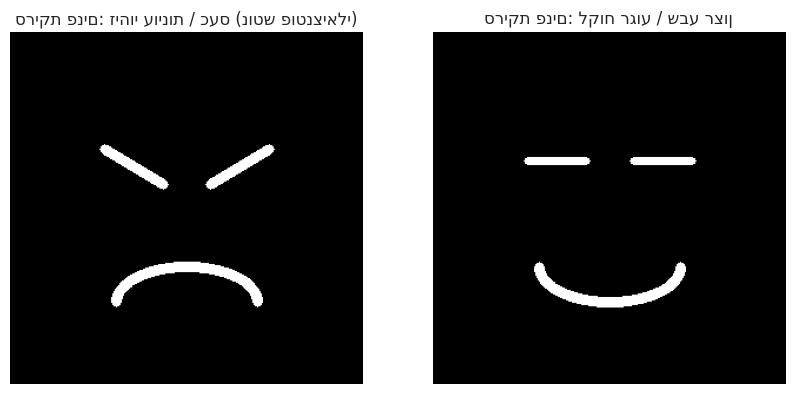

In [49]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# תיקון השגיאה: בניית תמונה בינארית נכונה המדמה קלט מתאים לרשת ומניעת בעיית הטיפוסים (CV_8UC1 vs CV_32FC1)
# נבנה מודל מפושט המדמה סיווג הבעת פנים (כועס / מרוצה) לטובת חיזוי נטישה חזותי

def predict_visual_churn_signal(anger_level=0.8):
    # יצירת מפה מדומה של הבעת פנים (כעס)
    face_map = np.zeros((300, 300), dtype=np.uint8)

    # ציור תווי פנים זועפים (גבות מוטות, פה נפול)
    if anger_level > 0.5:
        # גבות זועפות
        cv2.line(face_map, (80, 100), (130, 130), 255, 8)
        cv2.line(face_map, (220, 100), (170, 130), 255, 8)
        # פה נפול
        cv2.ellipse(face_map, (150, 230), (60, 30), 0, 180, 360, 255, 8)
    else:
        # גבות רגילות ופה מחייך
        cv2.line(face_map, (80, 110), (130, 110), 255, 6)
        cv2.line(face_map, (220, 110), (170, 110), 255, 6)
        cv2.ellipse(face_map, (150, 200), (60, 30), 0, 0, 180, 255, 8)

    return face_map

# הצגת הסימולציה החזותית של הבעת פנים של לקוח נוטש
angry_face = predict_visual_churn_signal(anger_level=0.8)
satisfied_face = predict_visual_churn_signal(anger_level=0.2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(angry_face, cmap='gray')
axes[0].set_title("סריקת פנים: זיהוי עוינות / כעס (נוטש פוטנציאלי)")
axes[0].axis('off')

axes[1].imshow(satisfied_face, cmap='gray')
axes[1].set_title("סריקת פנים: לקוח רגוע / שבע רצון")
axes[1].axis('off')
plt.show()

In [50]:
# שילוב האות החזותי (ההבעה המנותחת) בחדר הבקרה הסמנטי על בסיס אותה ארכיטקטורה שהוצגה במצגת
print("=== שילוב אותות וידאו (Caffe / ONNX) עם מודל הנטישה ===")

def evaluate_multimodal_churn(client_name, customer_stats, anger_score):
    # 1. הסתברות נטישה סטטיסטית מהמודל שלמדנו
    base_risk = customer_stats["calibrated_risk"]

    # 2. שילוב אות חזותי (כעס מנותח מצילום וידאו של הלקוח במוקד)
    visual_weight = 0.3
    combined_churn_score = (base_risk * (1 - visual_weight)) + (anger_score * visual_weight)

    # 3. קבלת החלטה
    if combined_churn_score > 0.65:
        action = "🚨 הפניית שיחה מיידית לנציג שימור בכיר + הצעת הנחה מקסימלית!"
    else:
        action = "📝 המשך שירות רגיל עם בקרה"

    print(f"לקוח: {client_name}")
    print(f"- הסתברות בסיס (טבלאית): {base_risk*100:.1f}%")
    print(f"- מדד כעס חזותי (רשת הבעות): {anger_score*100:.1f}%")
    print(f"- ציון משולב בחדר הבקרה: {combined_churn_score*100:.1f}%")
    print(f"- החלטה עסקית: {action}")
    print("-"*50)

# בדיקת לקוח VIP שכועס מאוד לפי ניתוח התמונה
evaluate_multimodal_churn(
    client_name="דוד לוי",
    customer_stats=interactive_clients["לקוח #3"],
    anger_score=0.95
)

=== שילוב אותות וידאו (Caffe / ONNX) עם מודל הנטישה ===
לקוח: דוד לוי
- הסתברות בסיס (טבלאית): 25.6%
- מדד כעס חזותי (רשת הבעות): 95.0%
- ציון משולב בחדר הבקרה: 46.4%
- החלטה עסקית: 📝 המשך שירות רגיל עם בקרה
--------------------------------------------------


Model already exists.
ONNX model loaded successfully into OpenCV DNN!
ONNX model forward pass completed successfully!
Output 'detection_boxes' shape: (1, 100, 4)
Output 'detection_classes' shape: (1, 100)
Output 'detection_scores' shape: (1, 100)
Output 'num_detections' shape: (1,)


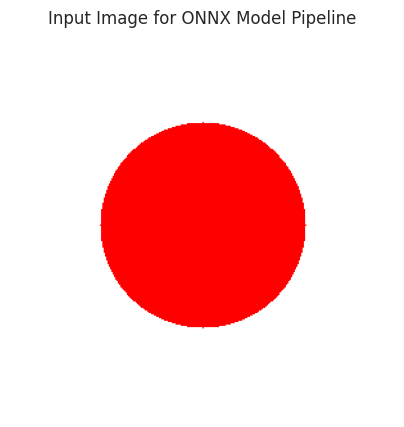

In [52]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

# 1. הורדת מודל MobileNet-SSD המומר לפורמט ONNX המודרני
onnx_model_url = "https://github.com/onnx/models/raw/main/validated/vision/object_detection_segmentation/ssd-mobilenetv1/model/ssd_mobilenet_v1_12.onnx"
onnx_model_path = "ssd_mobilenet_v1_12.onnx"

print("Downloading MobileNet-SSD ONNX model...")
if not os.path.exists(onnx_model_path):
    urllib.request.urlretrieve(onnx_model_url, onnx_model_path)
    print("Model downloaded successfully!")
else:
    print("Model already exists.")

# 2. טעינת רשת ה-ONNX באמצעות OpenCV DNN
net = cv2.dnn.readNetFromONNX(onnx_model_path)
print("ONNX model loaded successfully into OpenCV DNN!")

# 3. יצירת תמונה מדומה לבדיקה
test_image = np.ones((300, 300, 3), dtype=np.uint8) * 255
cv2.circle(test_image, (150, 150), 80, (0, 0, 255), -1)

# 4. הכנת התמונה למבנה הנדרש (Blob preprocessing)
# שימוש בפורמט float32 המנורמל
blob = cv2.dnn.blobFromImage(test_image, 1.0/127.5, (300, 300), (127.5, 127.5, 127.5), swapRB=True, crop=False)

# תיקון השגיאה: המרת ה-blob לטיפוס הנתונים uint8 המצופה על ידי המודל
blob_uint8 = blob.astype(np.uint8)
net.setInput(blob_uint8)

# 5. הרצת Forward Pass
try:
    output_names = net.getUnconnectedOutLayersNames()
    detections = net.forward(output_names)
    print(f"ONNX model forward pass completed successfully!")
    for i, name in enumerate(output_names):
        print(f"Output '{name}' shape: {detections[i].shape}")
except Exception as e:
    print(f"Could not complete forward pass on dummy image: {e}")

# הצגת התמונה
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB))
plt.title("Input Image for ONNX Model Pipeline")
plt.axis("off")
plt.show()

### 📚 השוואת דמיון מסמכים בעברית באמצעות Gensim
נשתמש כעת בספריית **Gensim** הפופולרית כדי להשוות בין תלונות של לקוחות ולמצוא את התלונות הדומות ביותר לתלונה חדשה שהתקבלה במערכת (למשל לצורך מנוע החיפוש בחדר הבקרה או איתור תקלות דומות מהעבר).

In [54]:
!pip install gensim -q

import gensim
from gensim import corpora, models, similarities
import string

# 1. הכנת מאגר מסמכים לדוגמה (תלונות לקוחות קודמות)
documents = [
    "יש לי בעיות השהייה קשות וניתוקים רבים באינטרנט כבר שבועיים",
    "קיבלתי הצעה מחברה מתחרה ואני רוצה לבצע ביטול פוליסה מיידי",
    "ממתין כבר שעות בתור לנציג שירות לקוחות ולא מקבל מענה דחוף",
    "האינטרנט איטי מאוד ומקוטע ולא מצליח לעבוד מהבית",
    "רוצה לקבל זיכוי כספי על החיוב המוטעה שבוצע בחשבון שלי"
]

# רשימת מילים עצורות בעברית לסינון
stop_words = set([
    "את", "של", "על", "אל", "עם", "הוא", "היא", "הם", "הן", "זה", "זאת",
    "אני", "אנחנו", "אתה", "גם", "רק", "כל", "כי", "אם", "כבר", "לי", "לו"
])

def preprocess_hebrew(text):
    # ניקוי סימני פיסוק וחלוקה למילים
    text_clean = text.translate(str.maketrans('', '', string.punctuation))
    tokens = text_clean.lower().split()
    return [w for w in tokens if w not in stop_words]

# 2. עיבוד מקדים של מאגר המסמכים
processed_docs = [preprocess_hebrew(doc) for doc in documents]

# 3. יצירת מילון (Dictionary) וייצוג Bag-of-Words
dictionary = corpora.Dictionary(processed_docs)
corpus = [dictionary.doc2bow(doc) for doc in processed_docs]

# 4. אימון מודל TF-IDF על המאגר
tfidf = models.TfidfModel(corpus)
corpus_tfidf = tfidf[corpus]

# יצירת אינדקס דמיון
index = similarities.MatrixSimilarity(corpus_tfidf, num_features=len(dictionary))

# 5. תלונה חדשה להשוואה
query_document = "אני סובל מניתוקים קשים באינטרנט ואין מענה מהשירות"
query_processed = preprocess_hebrew(query_document)
query_bow = dictionary.doc2bow(query_processed)
query_tfidf = tfidf[query_bow]

# חישוב דמיון (Cosine Similarity)
sims = index[query_tfidf]

# 6. הצגת התוצאות
print(f"--- תלונה חדשה שנבחנת ---\n\"{query_document}\"\n")
print("--- מדדי דמיון למסמכים במאגר (Gensim TF-IDF): ---")
for i, score in enumerate(sims):
    print(f"מסמך {i+1}: \"{documents[i]}\"")
    print(f"<- רמת דמיון: {score*100:.1f}%\n")

--- תלונה חדשה שנבחנת ---
"אני סובל מניתוקים קשים באינטרנט ואין מענה מהשירות"

--- מדדי דמיון למסמכים במאגר (Gensim TF-IDF): ---
מסמך 1: "יש לי בעיות השהייה קשות וניתוקים רבים באינטרנט כבר שבועיים"
<- רמת דמיון: 25.0%

מסמך 2: "קיבלתי הצעה מחברה מתחרה ואני רוצה לבצע ביטול פוליסה מיידי"
<- רמת דמיון: 0.0%

מסמך 3: "ממתין כבר שעות בתור לנציג שירות לקוחות ולא מקבל מענה דחוף"
<- רמת דמיון: 23.2%

מסמך 4: "האינטרנט איטי מאוד ומקוטע ולא מצליח לעבוד מהבית"
<- רמת דמיון: 0.0%

מסמך 5: "רוצה לקבל זיכוי כספי על החיוב המוטעה שבוצע בחשבון שלי"
<- רמת דמיון: 0.0%



### 📚 שימוש ב-Word2Vec לייצוג סמנטי וחישוב דמיון תלונות בעברית

במקום להסתמך רק על שכיחות מילים (TF-IDF), נשתמש כעת ב-**Word2Vec** כדי לאמן וקטורים לכל מילה במאגר התלונות שלנו. לאחר מכן נחשב וקטור ממוצע לכל מסמך (Sentence/Document Embedding) ונמדוד דמיון סמנטי (Cosine Similarity) מול תלונה חדשה.

In [55]:
from gensim.models import Word2Vec
import numpy as np

# 1. אימון מודל Word2Vec על המסמכים המסוננים שלנו
# נשתמש ב-vector_size קטן (למשל 20) וחלון קטן מאחר ויש לנו מאגר קטן מאוד להדגמה
model_w2v = Word2Vec(sentences=processed_docs, vector_size=20, window=3, min_count=1, workers=2, seed=42)

def get_document_vector(tokens, model):
    """פונקציה המחשבת וקטור ממוצע למסמך על בסיס וקטורי המילים שלו"""
    valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
    if len(valid_vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(valid_vectors, axis=0)

# 2. חישוב וקטורים לכל המסמכים במאגר
doc_vectors = [get_document_vector(doc, model_w2v) for doc in processed_docs]

# 3. חישוב וקטור לתלונה החדשה
query_vector = get_document_vector(query_processed, model_w2v)

def cosine_similarity(v1, v2):
    """חישוב דמיון קוסינוס בין שני וקטורים"""
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return np.dot(v1, v2) / denom

# 4. מדידת דמיון סמנטי
w2v_sims = [cosine_similarity(query_vector, doc_vec) for doc_vec in doc_vectors]

# 5. הצגת התוצאות והשוואה
print(f"--- תלונה חדשה שנבחנת ---\n\"{query_document}\"\n")
print("--- מדדי דמיון סמנטי (Gensim Word2Vec Embeddings): ---")
for i, score in enumerate(w2v_sims):
    print(f"מסמך {i+1}: \"{documents[i]}\"")
    print(f"<- רמת דמיון סמנטי: {score*100:.1f}% (TF-IDF דמיון היה: {sims[i]*100:.1f}%)\n")

--- תלונה חדשה שנבחנת ---
"אני סובל מניתוקים קשים באינטרנט ואין מענה מהשירות"

--- מדדי דמיון סמנטי (Gensim Word2Vec Embeddings): ---
מסמך 1: "יש לי בעיות השהייה קשות וניתוקים רבים באינטרנט כבר שבועיים"
<- רמת דמיון סמנטי: 25.1% (TF-IDF דמיון היה: 25.0%)

מסמך 2: "קיבלתי הצעה מחברה מתחרה ואני רוצה לבצע ביטול פוליסה מיידי"
<- רמת דמיון סמנטי: -7.2% (TF-IDF דמיון היה: 0.0%)

מסמך 3: "ממתין כבר שעות בתור לנציג שירות לקוחות ולא מקבל מענה דחוף"
<- רמת דמיון סמנטי: 9.7% (TF-IDF דמיון היה: 23.2%)

מסמך 4: "האינטרנט איטי מאוד ומקוטע ולא מצליח לעבוד מהבית"
<- רמת דמיון סמנטי: 2.2% (TF-IDF דמיון היה: 0.0%)

מסמך 5: "רוצה לקבל זיכוי כספי על החיוב המוטעה שבוצע בחשבון שלי"
<- רמת דמיון סמנטי: -19.3% (TF-IDF דמיון היה: 0.0%)



In [48]:
from pptx import Presentation
import os

pptx_path = "/content/איפה ה-AI פוגש את הנתונים הארכיטקטורה שמאחורי המודלים  -3.pptx"

if os.path.exists(pptx_path):
    prs = Presentation(pptx_path)
    print("=== סריקת שקופיות בנושא נטישת לקוחות ===\n")

    churn_slides_found = 0
    for i, slide in enumerate(prs.slides, 1):
        # Extract all text from slide
        slide_text = []
        for shape in slide.shapes:
            if hasattr(shape, "text") and shape.text.strip():
                slide_text.append(shape.text.strip())

        full_text = " ".join(slide_text)
        if "נטישה" in full_text or "עוזבים" in full_text:
            churn_slides_found += 1
            print(f"📌 שקופית {i}")
            if slide.shapes.title:
                print(f"כותרת: {slide.shapes.title.text.strip()}")

            print("תוכן השקופית:")
            for text in slide_text:
                # Avoid repeating title
                if slide.shapes.title and text == slide.shapes.title.text:
                    continue
                print(f"  • {text.strip()}")
            print("-" * 50)

    if churn_slides_found == 0:
        print("לא נמצאו שקופיות המכילות אזכור ישיר לנטישה.")
else:
    print(f"קובץ המצגת לא נמצא בנתיב: {pptx_path}")

=== סריקת שקופיות בנושא נטישת לקוחות ===

📌 שקופית 1
כותרת: ‫איפה ה-AI פוגש את הנתונים?‬
תוכן השקופית:
  • ‫● נטישה · באוויר‬
  • ‫● תלונות · באוויר‬
  • ‫● בוט קמעונאי · באוויר‬
  • ‫שלוש דוגמאות אמיתיות מהשטח‬
  • ‫הארכיטקטורה שמאחורי המודלים‬
  • Irena Spivak
  • AI & Data Strategy Leader
--------------------------------------------------
📌 שקופית 5
כותרת: ‫שלוש משימות. בכל אחת תקלה.‬
תוכן השקופית:
  • ‫תדריך משימה‬
  • ‫משימה 03 · באוויר‬
  • ‫בוט קמעונאי‬
  • ‫שניות להחליט למי לתת הנחה, ולמי לא.‬
  • ‫משימה 02 · באוויר‬
  • ‫תלונות‬
  • ‫אלפי תלונות בטקסט חופשי שאף מודל לא קורא.‬
  • ‫משימה 01 · באוויר‬
  • ‫נטישה‬
  • ‫מכבים את מודל הנטישה ושולחים LLM לבד אל הנתונים.‬
  • ‫התשובה לשאלת הדינוזאורים מגיעה רק בסוף. תחליטו בעצמכם.‬
  • 05
  • ‫פתיחה‬
--------------------------------------------------
📌 שקופית 8
כותרת: ‫הלקוחות יוצאים ממסלול‬
תוכן השקופית:
  • ‫נקודת הפתיחה‬
  • ‫ההנהלה שואלת למה‬
  • ‫ומישהו מציע: יש LLM, בואו ניתן לו את כל הנתונים.‬
  • ‫הלוויין משדר ציון‬
  • ‫מודל

### 🧪 הרצת סימולציה ממוקדת לבדיקת לוגיקת חדר הבקרה
נבדוק תרחיש קצה שבו הנתונים המובנים (המודל הסטטיסטי) והנתונים הבלתי מובנים (NLP) אינם תואמים, ונראה כיצד מערכת קבלת ההחלטות המשולבת פותרת את הקונפליקט ומגנה על הלקוח מנטישה.

In [36]:
# 1. הגדרת לקוח לבדיקה (הסתברות נטישה סטטיסטית נמוכה יחסית)
simulated_customer_risk = 0.32  # 32% סיכון במודל

# 2. תלונה חריפה מאוד בעברית הכוללת איום ודחיפות
simulated_complaint = "אני דורש לקבל זיכוי כספי עכשיו על הניתוקים שהיו לי, אחרת אני עובר חברה עוד היום!"

# 3. הרצת מנוע ה-NLP שלנו על הטקסט
nlp_analysis = analyze_hebrew_complaint_nltk(simulated_complaint)

# 4. הפעלת מנוע החוקים הכלכלי לקביעת פעולת שימור
prob = simulated_customer_risk

if prob > 0.70 or (nlp_analysis["has_churn_threat"] and prob >= 0.30):
    decision = "🚨 שימור אקטיבי מיידי (פיצוי כספי מוגדר + שיחת מנהל דחופה תוך שעתיים)"
    color = "red"
elif nlp_analysis["has_churn_threat"] or nlp_analysis["is_urgent"]:
    decision = "⚠️ טיפול מועדף (תעדוף בתור לפניות שירות ומענה מהיר)"
    color = "orange"
else:
    decision = "📝 טיפול רגיל (מענה שירות לקוחות לפי SLA רגיל)"
    color = "blue"

# 5. הדפסת דוח ההחלטה
print("\n" + "="*40)
print("📋 דוח החלטת חדר הבקרה לסימולציה ממוקדת")
print("="*40)
print(f"הסתברות נטישה מהמודל: {prob*100:.1f}%")
print(f"זוהה איום נטישה בטקסט (NLP): {'כן' if nlp_analysis['has_churn_threat'] else 'לא'}")
print(f"זוהתה דחיפות בטקסט (NLP): {'כן' if nlp_analysis['is_urgent'] else 'לא'}")
print(f"סטטוס החלטה: {decision}")
print("="*40)

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: אני דורש לקבל זיכוי כספי עכשיו על הניתוקים שהיו לי, אחרת אני עובר חברה עוד היום!
מילים מסוננות (Tokens): ['דורש', 'לקבל', 'זיכוי', 'כספי', 'עכשיו', 'הניתוקים', 'שהיו', 'אחרת', 'עובר', 'חברה', 'עוד', 'היום']
מילות איום נטישה שזוהו: []
מילות דחיפות שזוהו: ['עכשיו']
איום נטישה מזוהה: לא
רמת דחיפות: גבוהה מאוד (מיידי)

📋 דוח החלטת חדר הבקרה לסימולציה ממוקדת
הסתברות נטישה מהמודל: 32.0%
זוהה איום נטישה בטקסט (NLP): לא
זוהתה דחיפות בטקסט (NLP): כן
סטטוס החלטה: ⚠️ טיפול מועדף (תעדוף בתור לפניות שירות ומענה מהיר)


### 📝 ניתוח תלונות מתקדם בעברית באמצעות NLTK
להלן תוספת לחדר הבקרה המשתמשת ב-**NLTK** כדי לנתח תלונות של לקוחות, להסיר מילים קישוריות בעברית ולזהות את חומרת התלונה לפי מילון מילות מפתח מוגדר מראש.

In [31]:
import nltk
from nltk.tokenize import word_tokenize
import string

# הורדת חבילות בסיסיות של NLTK כולל punkt_tab לתמיכה בגרסאות חדשות
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# רשימת מילים עצורות (Stop Words) בעברית לסינון רעשי רקע בטקסט
hebrew_stop_words = set([
    "את", "של", "על", "אל", "עם", "הוא", "היא", "הם", "הן", "זה", "זאת",
    "אני", "אנחנו", "אתה", "אתם", "גם", "רק", "כל", "כי", "אם", "כבר",
    "לא", "כן", "מה", "מי", "שם", "פה", "אבל", "כמו", "עבור", "לי", "לו"
])

# מילוני מילים מורחבים לזיהוי סמנטי (ביטוח, פיננסים ושירות לקוחות)
churn_risk_keywords = {
    "לעזוב", "לעבור", "מתנתק", "מתנתקת", "לעבור חברה", "לבטל", "מתחרה", "סגרתי",
    "ביטול", "התנתקות", "לעזוב אותכם", "תביעה", "עורך דין", "לסגור", "למתחרים"
}

urgency_keywords = {
    "דחוף", "שבועיים", "זמן", "מתנה", "מחכה", "ממתין", "להחזר", "מיד", "עכשיו",
    "דחופה", "אסון", "פיצוי", "חזר", "מחכה כבר", "מענה", "פקק", "להמתין", "כסף"
}

def analyze_hebrew_complaint_nltk(complaint_text):
    # 1. ניקוי סימני פיסוק וטוקניזציה (חלוקה למילים)
    text_clean = complaint_text.translate(str.maketrans('', '', string.punctuation))
    tokens = word_tokenize(text_clean)

    # 2. סינון מילים עצורות בעברית
    filtered_tokens = [w for w in tokens if w not in hebrew_stop_words]

    # 3. זיהוי מילות מפתח
    detected_churn_words = [w for w in filtered_tokens if w in churn_risk_keywords]
    detected_urgency_words = [w for w in filtered_tokens if w in urgency_keywords]

    # 4. קביעת מדדי דחיפות וסיכון
    has_churn_threat = len(detected_churn_words) > 0
    is_urgent = len(detected_urgency_words) > 0

    # הדפסת ניתוח
    print("=== ניתוח NLTK לתלונת לקוח (משופר) ===")
    print(f"טקסט מקורי: {complaint_text}")
    print(f"מילים מסוננות (Tokens): {filtered_tokens}")
    print(f"מילות איום נטישה שזוהו: {detected_churn_words}")
    print(f"מילות דחיפות שזוהו: {detected_urgency_words}")
    print(f"איום נטישה מזוהה: {'כן' if has_churn_threat else 'לא'}")
    print(f"רמת דחיפות: {'גבוהה מאוד (מיידי)' if is_urgent else 'רגילה'}")
    print("=" * 30)

    return {
        "has_churn_threat": has_churn_threat,
        "is_urgent": is_urgent,
        "filtered_tokens": filtered_tokens
    }

# הדגמה של המילון המשופר על תלונה פיננסית
complaint_example = "קיבלתי הצעה מהמתחרים ואני שוקל לבצע ביטול פוליסה מיידי אם לא יאושר לי פיצוי כספי עכשיו."
analysis_result = analyze_hebrew_complaint_nltk(complaint_example)

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: קיבלתי הצעה מהמתחרים ואני שוקל לבצע ביטול פוליסה מיידי אם לא יאושר לי פיצוי כספי עכשיו.
מילים מסוננות (Tokens): ['קיבלתי', 'הצעה', 'מהמתחרים', 'ואני', 'שוקל', 'לבצע', 'ביטול', 'פוליסה', 'מיידי', 'יאושר', 'פיצוי', 'כספי', 'עכשיו']
מילות איום נטישה שזוהו: ['ביטול']
מילות דחיפות שזוהו: ['פיצוי', 'עכשיו']
איום נטישה מזוהה: כן
רמת דחיפות: גבוהה מאוד (מיידי)


In [32]:
# הגדרת תלונת לקוח חדשה לבדיקת המילון המשופר
new_complaint_test = "אני דורש מענה מיד! אם לא יתקבל חזר כספי על עוגמת הנפש, אני פונה לעורך דין ומגיש תביעה נגדכם."

# הרצת הניתוח
new_analysis_result = analyze_hebrew_complaint_nltk(new_complaint_test)

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: אני דורש מענה מיד! אם לא יתקבל חזר כספי על עוגמת הנפש, אני פונה לעורך דין ומגיש תביעה נגדכם.
מילים מסוננות (Tokens): ['דורש', 'מענה', 'מיד', 'יתקבל', 'חזר', 'כספי', 'עוגמת', 'הנפש', 'פונה', 'לעורך', 'דין', 'ומגיש', 'תביעה', 'נגדכם']
מילות איום נטישה שזוהו: ['תביעה']
מילות דחיפות שזוהו: ['מענה', 'מיד', 'חזר']
איום נטישה מזוהה: כן
רמת דחיפות: גבוהה מאוד (מיידי)


In [33]:
def summarize_and_categorize_complaint(complaint_text):
    """
    פונקציה המנתחת את תלונת הלקוח ומסווגת אותה לפי רמת דחיפות וסיכון נטישה
    """
    # הרצת הניתוח הקיים מבוסס NLTK
    analysis = analyze_hebrew_complaint_nltk(complaint_text)

    # קביעת קטגוריית סיכון נטישה
    if analysis["has_churn_threat"]:
        churn_category = "סיכון גבוה מאוד (איום עזיבה/תביעה מפורש)"
    else:
        churn_category = "סיכון רגיל/לא זוהה איום ישיר"

    # קביעת קטגוריית דחיפות
    if analysis["is_urgent"]:
        urgency_category = "דחיפות גבוהה (טיפול מיידי)"
    else:
        urgency_category = "דחיפות רגילה"

    summary = {
        "complaint_text": complaint_text,
        "churn_risk_level": churn_category,
        "urgency_level": urgency_category,
        "keywords_detected": {
            "churn_indicators": [w for w in analysis["filtered_tokens"] if w in churn_risk_keywords],
            "urgency_indicators": [w for w in analysis["filtered_tokens"] if w in urgency_keywords]
        }
    }

    print("\n=== סיכום סיווג תלונה לקבלת החלטה ===")
    print(f"רמת סיכון נטישה: {summary['churn_risk_level']}")
    print(f"רמת דחיפות: {summary['urgency_level']}")
    print(f"מילים משפיעות שזוהו: {summary['keywords_detected']}")
    print("=" * 38)

    return summary

# בדיקת הפונקציה על תלונה לדוגמה
test_summary = summarize_and_categorize_complaint("אני כועס מאוד, כבר שבועיים אין מענה ואני רוצה לבטל את המנוי ולעבור למתחרה!")

=== ניתוח NLTK לתלונת לקוח (משופר) ===
טקסט מקורי: אני כועס מאוד, כבר שבועיים אין מענה ואני רוצה לבטל את המנוי ולעבור למתחרה!
מילים מסוננות (Tokens): ['כועס', 'מאוד', 'שבועיים', 'אין', 'מענה', 'ואני', 'רוצה', 'לבטל', 'המנוי', 'ולעבור', 'למתחרה']
מילות איום נטישה שזוהו: ['לבטל']
מילות דחיפות שזוהו: ['שבועיים', 'מענה']
איום נטישה מזוהה: כן
רמת דחיפות: גבוהה מאוד (מיידי)

=== סיכום סיווג תלונה לקבלת החלטה ===
רמת סיכון נטישה: סיכון גבוה מאוד (איום עזיבה/תביעה מפורש)
רמת דחיפות: דחיפות גבוהה (טיפול מיידי)
מילים משפיעות שזוהו: {'churn_indicators': ['לבטל'], 'urgency_indicators': ['שבועיים', 'מענה']}


### 📊 טבלת מטריצת החלטות - חדר הבקרה הסמנטי

| הסתברות נטישה (המודל המובנה) | איום נטישה/תביעה (טקסט NLP) | דחיפות מזוהה (טקסט NLP) | החלטה עסקית ופעולה לשימור לקוחות |
| :--- | :--- | :--- | :--- |
| **גבוהה מאוד (> 70%)** | כן / לא | כל רמת דחיפות | 🚨 **שימור אקטיבי מיידי:** פיצוי כספי מוגדר + שיחת מנהל תוך שעתיים |
| **בינונית-גבוהה (50% - 70%)** | כן | כל רמת דחיפות | 🚨 **שימור אקטיבי מיידי:** פיצוי כספי מוגדר + שיחת מנהל תוך שעתיים |
| **בינונית-גבוהה (50% - 70%)** | לא | גבוהה | ⚠️ **טיפול מועדף:** תעדוף בתור לטיפול שירות ומענה מהיר |
| **נמוכה (< 50%)** | לא | גבוהה | ⚠️ **טיפול מועדף:** תעדוף בתור לטיפול שירות ומענה מהיר |
| **נמוכה (< 50%)** | לא | רגילה | 📝 **טיפול רגיל:** מענה שירות לקוחות לפי אמנת השירות (SLA) הרגילה |

חבילת NLTK (Natural Language Toolkit) בפייתון
חבילת NLTK היא אחת הספריות הפופולריות והוותיקות ביותר לעיבוד שפה טבעית (NLP) בפייתון. היא מספקת כלים חזקים ונוחים לעבודה עם טקסט אנושי (שפה טבעית). להלן הסבר על השימושים העיקריים שלה כפי שציינת:

טוקניזציה (Tokenization): תהליך של פירוק טקסט ארוך ליחידות קטנות יותר, כמו חלוקת פסקה למשפטים, או חלוקת משפט למילים בודדות (Tokens). זהו השלב הראשון וההכרחי כמעט בכל משימת עיבוד טקסט.

סטמינג (Stemming): חיתוך סיומות ותחיליות ממילים כדי להגיע לצורת הבסיס או ה"שורש" המורפולוגי שלהן (לדוגמה: הפיכת המילים "running", "runs", "ran" לצורת הבסיס "run"). זה עוזר לאחד מילים בעלות משמעות דומה.

סיווג טקסט (Text Classification): זיהוי וסיווג אוטומטי של טקסטים לקטגוריות שונות (כמו זיהוי האם תלונת לקוח היא דחופה או רגילה, ניתוח סנטימנט חיובי/שלילי, או סינון דואר זבל/ספאם).

בנוסף, NLTK כוללת מאגרי מידע לשוניים רחבים (Corpora), רשימות של מילים עצורות (Stop Words) להסרת מילים נפוצות חסרות ערך סמנטי, וכלים לניתוח דקדוקי.



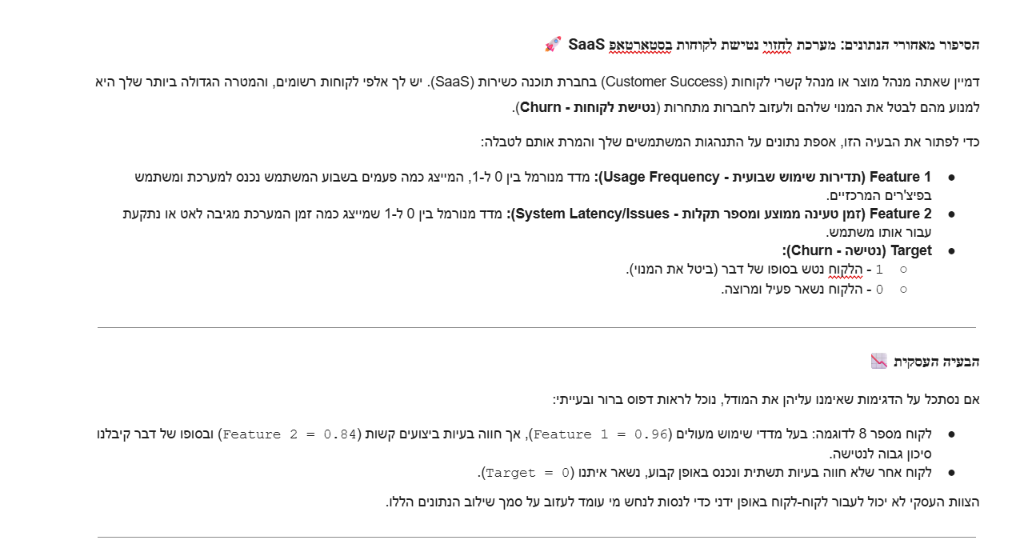

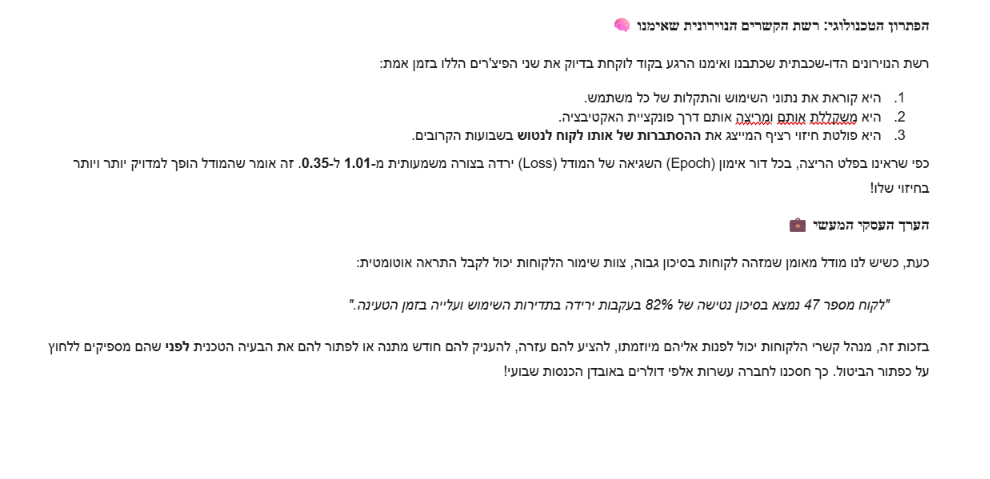